# Part D : prédiction glycémie élevée

## Introduction

## 1. Chargement

In [1]:
import sklearn
import seaborn
import matplotlib.pyplot as plt
from pandas import *
import janitor
from IPython.display import display
import math
import numpy as np

In [2]:
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

import shap

/Users/ismail/workspace/formation@data/common_core/applications/01_integrated_project/python/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
df_antecedents_familiaux = read_csv("../../csv/Antecedents_familiaux.csv").clean_names(strip_underscores=True)
df_centres_soins = read_csv("../../csv/Centres_soins.csv").clean_names(strip_underscores=True)
df_consultations = read_csv("../../csv/Consultations.csv").clean_names(strip_underscores=True)
df_expression_genique = read_csv("../../csv/Expression_genique.csv").clean_names(strip_underscores=True)
df_historique_glycemique = read_csv("../../csv/Historique_glycemique.csv").clean_names(strip_underscores=True)
df_hygiene_vie = read_csv("../../csv/Hygiene_vie.csv").clean_names(strip_underscores=True)
df_patients_centres = read_csv("../../csv/Patients_centres.csv").clean_names(strip_underscores=True)
df_patients = read_csv("../../csv/Patients.csv").clean_names(strip_underscores=True)
df_traitements = read_csv("../../csv/Traitements.csv").clean_names(strip_underscores=True)

In [4]:
df_dict = {
    "antecedents_familiaux": df_antecedents_familiaux,
    "centres_soins": df_centres_soins,
    "consultations": df_consultations,
    "expression_genique": df_expression_genique,
    "historique_glycemique": df_historique_glycemique,
    "hygiene_vie": df_hygiene_vie,
    "patients_centres": df_patients_centres,
    "patients": df_patients,
    "traitements": df_traitements,
}

## 2. Exploration préliminaire

(voir src/project_d/exploration.ipynb)

## 3. Nettoyage préliminaire

In [5]:
## nettoyage de la table df_patient

# on nettoie les valeurs catégoriques

df_patients["sexe"].value_counts(dropna=False)

sexe
F        923
M        561
NaN        4
femme      3
homme      2
Femme      2
f          1
m          1
H          1
h          1
na         1
Name: count, dtype: int64

In [6]:
mapping: dict[str, str] = {"m": "M", "h": "M", "homme": "M",
           "f": "F", "femme": "F"}
df_patients["sexe"] = df_patients["sexe"].str.strip().str.lower().map(mapping).fillna("Unknown")

In [7]:
df_patients["sexe"].value_counts(dropna=False)

sexe
F          929
M          566
Unknown      5
Name: count, dtype: int64

In [8]:
df_patients["corticoides"].value_counts(dropna=False)

corticoides
Non    1364
Oui     128
NaN       6
na        1
Na        1
Name: count, dtype: int64

In [9]:
df_patients["corticoides"].value_counts(dropna=False)

mapping = {"na":"Non", "":"Non", "non":"Non", "oui":"Oui"}

df_patients["corticoides"] = df_patients["corticoides"].str.strip().str.lower().map(mapping).fillna("Non")

display(df_patients["corticoides"].value_counts(dropna=False))

corticoides
Non    1372
Oui     128
Name: count, dtype: int64

In [10]:
df_patients["groupe_sanguin"].value_counts(dropna=False)

groupe_sanguin
O+     593
A+     426
B+     184
AB+    107
O-      82
A-      61
AB-     33
B-      14
Name: count, dtype: int64

In [11]:
df_patients["age_ans"].value_counts()

age_ans
18     49
58     39
45     38
61     38
62     37
       ..
19      6
81      5
80      5
23      5
278     1
Name: count, Length: 69, dtype: int64

In [12]:
df_patients["age_ans"] = df_patients["age_ans"].clip(upper=110)
df_patients["age_ans"].value_counts()

age_ans
18     49
58     39
45     38
61     38
62     37
       ..
19      6
81      5
80      5
23      5
110     1
Name: count, Length: 69, dtype: int64

### `Hygiène de vie`

In [13]:
df_hygiene_vie["stress_0_10"].value_counts()

stress_0_10
5     270
6     251
4     209
7     169
3     152
8     125
2     103
0      60
9      60
1      55
10     46
Name: count, dtype: int64

In [14]:
df_hygiene_vie["stress_0_10"].value_counts()

stress_0_10
5     270
6     251
4     209
7     169
3     152
8     125
2     103
0      60
9      60
1      55
10     46
Name: count, dtype: int64

In [15]:
df_hygiene_vie["niveau_de_stress"].value_counts()

niveau_de_stress
Modéré    730
Élevé     400
Faible    370
Name: count, dtype: int64

In [16]:
display("avant", df_hygiene_vie["niveau_dactivite"].value_counts())
mapping = {"élevée":"Élevée", "modérée":"Modérée", "faible":"Faible"}
df_hygiene_vie["niveau_dactivite"] = df_hygiene_vie["niveau_dactivite"].str.strip().str.lower().map(mapping)
display("après", df_hygiene_vie["niveau_dactivite"].value_counts())

'avant'

niveau_dactivite
Élevée     731
Modérée    456
Faible     312
faible       1
Name: count, dtype: int64

'après'

niveau_dactivite
Élevée     731
Modérée    456
Faible     313
Name: count, dtype: int64

In [17]:
display("avant", df_hygiene_vie["tabagisme"].value_counts(dropna=False))

'avant'

tabagisme
Non    1211
Oui     289
Name: count, dtype: int64

In [18]:
df_hygiene_vie["sommeil_h_nuit"].describe()

## un maximum a 64 est impossible pour un nombre d'heure de sommeil
## on clip à 24

df_hygiene_vie["sommeil_h_nuit"] = df_hygiene_vie["sommeil_h_nuit"].clip(upper=24)

(array([  8.,  46., 132., 260., 400., 332., 209.,  79.,  27.,   7.]),
 array([5.43  , 5.7158, 6.0016, 6.2874, 6.5732, 6.859 , 7.1448, 7.4306,
        7.7164, 8.0022, 8.288 ]),
 <BarContainer object of 10 artists>)

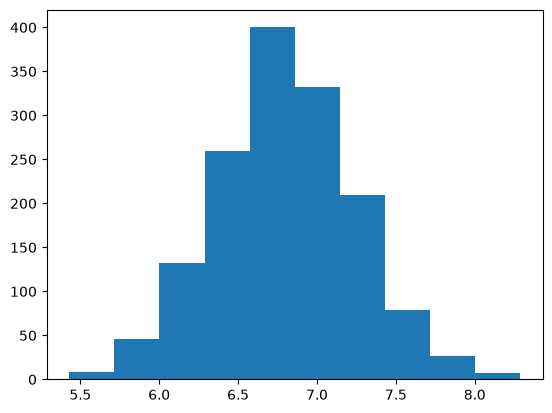

In [19]:
df_expression_genique["abcc8"]
plt.hist(df_expression_genique["abcc8"])

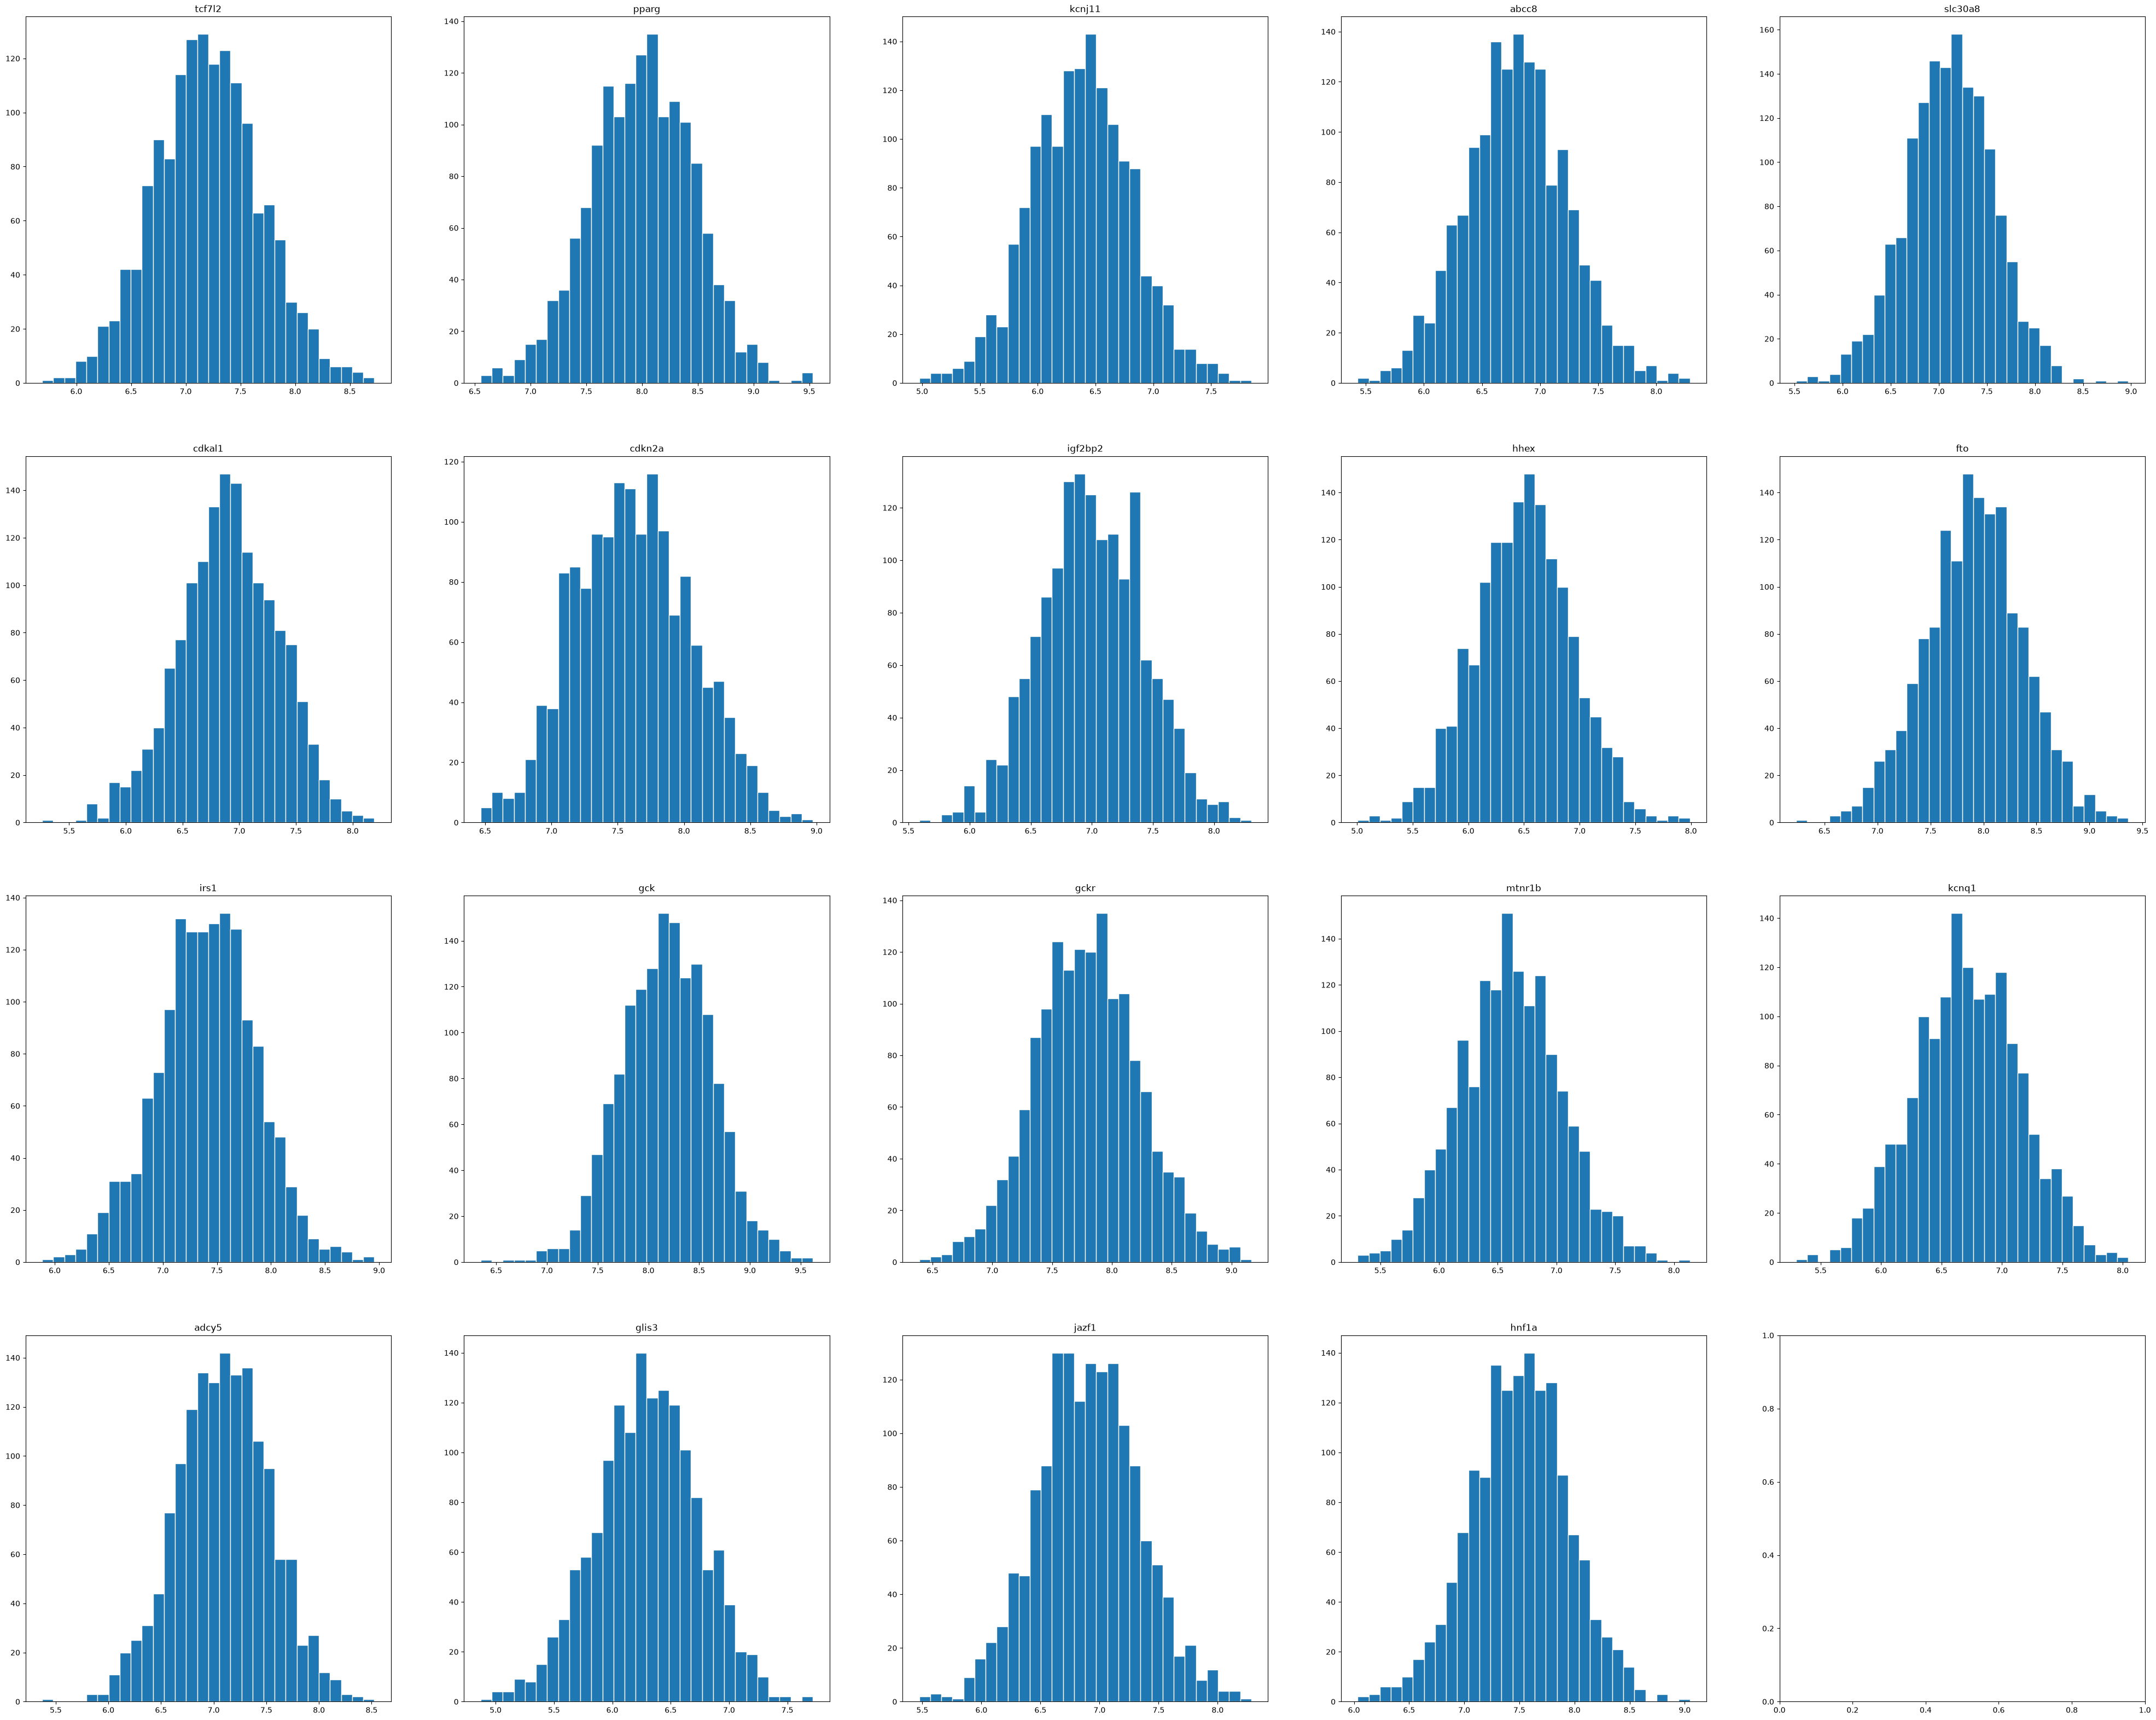

In [20]:
genes = df_expression_genique.select_dtypes("number").columns  # exclut id_patient
ncols = 5
nrows = math.ceil(len(genes) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(10 * ncols, 10 * nrows))
axes = axes.flatten()

for ax, gene in zip(axes, genes):
    ax.hist(df_expression_genique[gene].dropna(), bins=30, edgecolor="white")
    ax.set_title(gene)

plt.show()

In [21]:
df_antecedents_familiaux.count()

id_patient         1662
lien_de_parente    1662
pathologie         1662
dtype: int64

In [22]:
display(df_antecedents_familiaux.duplicated().sum())
display(df_antecedents_familiaux[df_antecedents_familiaux.duplicated(keep=False)])

np.int64(10)

,id_patient,lien_de_parente,pathologie
9,P010,Sœur,Hypertension
10,P010,Sœur,Hypertension
159,P148,Sœur,Obésité
160,P148,Sœur,Obésité
176,P162,Grand-parent,Maladie cardiovasculaire
177,P162,Grand-parent,Maladie cardiovasculaire
536,P486,Mère,Diabète de type 2
537,P486,Mère,Diabète de type 2
814,P741,Sœur,Diabète de type 2
816,P741,Sœur,Diabète de type 2


Je remarque des duplicates au niveau du lien de parenté et de la pathologie de certains patients. Comme je ne peux pas savoir si ce sont les mêmes personnes ou non fautes d'id sur les antécédents, je décide de les supprimer. Ce ne sont que 10 lignes floues sur 1662 lignes. 

In [23]:
df_antecedents_familiaux["lien_de_parente"].value_counts()

lien_de_parente
Aucun           1222
Grand-parent      97
Frère             93
Sœur              89
Mère              83
Père              78
Name: count, dtype: int64

In [24]:
df_antecedents_familiaux["pathologie"].value_counts(dropna=False)

pathologie
Aucun antécédent connu      1222
Diabète de type 2            146
Hypertension                 117
Obésité                       89
Maladie cardiovasculaire      88
Name: count, dtype: int64

In [25]:
df_consultations["type_de_consultation"].value_counts(dropna=False)

type_de_consultation
Médecine générale       893
Suivi diabétologique    824
Endocrinologie          801
Diététique              784
Prévention              161
Bilan                   146
Name: count, dtype: int64

In [26]:
df_consultations["medecin_service"].value_counts(dropna=False)

medecin_service
Médecine générale          893
Service de diabétologie    824
Endocrinologie             801
Diététicien·ne             784
Consultation prévention    161
Médecine interne           146
Name: count, dtype: int64

In [27]:
df_patients_centres["id_centre"].value_counts(dropna=False)

id_centre
C09    84
C08    73
C06    72
C03    70
C05    69
C15    68
C12    67
C20    66
C23    66
C19    65
C24    63
C01    62
C13    61
C07    61
C22    60
C11    60
C16    57
C17    57
C14    56
C18    56
C02    56
C04    53
C10    52
C21    46
Name: count, dtype: int64

In [28]:
df_patients_centres["id_patient"].count()

np.int64(1500)

## 4. Jointure des tables

### On agrege d'abord les tables avec plusieurs lignes par patients

In [29]:
mapping = {"aucun antécédent connu":"aucun_antecedent_connu", "diabète de type 2":"diabete_type_2", "hypertension":"hypertension", "maladie cardiovasculaire":"maladie_cardiovasculaire", "obésité":"obesite"}

df_antecedents_familiaux["pathologie"] = df_antecedents_familiaux["pathologie"].str.strip().str.lower().map(mapping)

In [30]:
display(df_antecedents_familiaux.duplicated().sum())
display(df_antecedents_familiaux[df_antecedents_familiaux.duplicated(keep=False)])
# on a des duplicates donc on les supprimes
df_antecedents_familiaux = df_antecedents_familiaux.drop_duplicates()


np.int64(10)

,id_patient,lien_de_parente,pathologie
9,P010,Sœur,hypertension
10,P010,Sœur,hypertension
159,P148,Sœur,obesite
160,P148,Sœur,obesite
176,P162,Grand-parent,maladie_cardiovasculaire
177,P162,Grand-parent,maladie_cardiovasculaire
536,P486,Mère,diabete_type_2
537,P486,Mère,diabete_type_2
814,P741,Sœur,diabete_type_2
816,P741,Sœur,diabete_type_2


On ne sait pas si ces duplicates sont légitimes ou non car nous n'avons pas de tables regroupant les ids des membres de la famille. Donc nous supposons, sur base des doubles `Père` et `Mère` que ce sont des erreurs. Quand bien même ça ne l'était pas, nous n'en avons que 10. 

In [31]:
df_antecedents_familiaux_wide = crosstab(df_antecedents_familiaux["id_patient"], df_antecedents_familiaux["pathologie"])
display(df_antecedents_familiaux_wide)
display(df_antecedents_familiaux_wide.shape)
## on peut drop aucun antecédent connu car inférer des autres colonnes
df_antecedents_familiaux_wide = df_antecedents_familiaux_wide.drop(columns="aucun_antecedent_connu")
display(df_antecedents_familiaux_wide.shape)

pathologie,aucun_antecedent_connu,diabete_type_2,hypertension,maladie_cardiovasculaire,obesite
id_patient,,,,,
P001,1,0,0,0,0
P002,0,0,1,0,0
P003,1,0,0,0,0
P004,1,0,0,0,0
P005,1,0,0,0,0
...,...,...,...,...,...
P995,1,0,0,0,0
P996,1,0,0,0,0
P997,1,0,0,0,0


(1500, 5)

(1500, 4)

In [32]:
df_full = (
  df_patients
  .merge(df_hygiene_vie, on="id_patient", how="left")
  .merge(df_antecedents_familiaux_wide, on="id_patient", how="left")
  .merge(df_expression_genique, on="id_patient", how="left")
)
df_full = df_full.set_index("id_patient")

In [33]:
display(df_full.shape)
display(df_full.isna().sum()[df_full.isna().sum() > 0])
display(df_full.count())

(1500, 43)

Series([], dtype: int64)

age_ans                            1500
sexe                               1500
poids_kg                           1500
taille_cm                          1500
groupe_sanguin                     1500
glycemie_mg_dl                     1500
insuline_µui_ml                    1500
corticoides                        1500
stress_0_10                        1500
niveau_de_stress                   1500
sommeil_h_nuit                     1500
activite_physique_min_sem          1500
niveau_dactivite                   1500
fruits_et_legumes_portions_jour    1500
boissons_sucrees_portions_sem      1500
fast_food_repas_sem                1500
score_alimentation_0_10            1500
qualite_de_lalimentation           1500
tabagisme                          1500
alcool_unites_sem                  1500
diabete_type_2                     1500
hypertension                       1500
maladie_cardiovasculaire           1500
obesite                            1500
tcf7l2                             1500


## 5. Création de la target

In [34]:
# on cree notre dataframe y avec notre nouvelle variable
# target "diabète" quand la glycemie est supérieure à 126 mg/dL.
# on part de df_full pour que y soit indexé par id_patient, comme X.

y = (df_full["glycemie_mg_dl"] >= 126).astype(int).rename("diabete")

display(y)

id_patient
P001     0
P002     0
P003     0
P004     0
P005     0
        ..
P1496    0
P1497    0
P1498    0
P1499    0
P1500    0
Name: diabete, Length: 1500, dtype: int64

## 6. Séparation du dataset

In [35]:
# On retire la target du dataset

X = df_full.drop(columns="glycemie_mg_dl")

In [36]:
from sklearn.model_selection import train_test_split

# on utilise stratify pour avoir la meme proportion de cas positif et négatif dans le train et le test dataset.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [37]:
display(X_train.shape)
display(X_train.head())
display(X_test.shape)
display(y_train.shape)
display(y_test.shape)

(1200, 42)

,age_ans,sexe,poids_kg,taille_cm,groupe_sanguin,insuline_µui_ml,corticoides,stress_0_10,niveau_de_stress,sommeil_h_nuit,...,fto,irs1,gck,gckr,mtnr1b,kcnq1,adcy5,glis3,jazf1,hnf1a
id_patient,,,,,,,,,,,,,,,,,,,,,
P714,30,M,71.2,190.2,AB+,6.0,Non,4,Modéré,9.9,...,8.191,6.922,7.233,8.233,5.760,6.527,7.549,6.599,6.590,7.802
P650,65,F,79.8,180.4,O+,5.7,Oui,5,Modéré,8.7,...,7.302,7.453,7.859,8.842,7.065,7.017,7.030,5.832,6.894,7.491
P712,51,F,63.8,152.8,A+,11.2,Non,0,Faible,6.9,...,7.199,7.989,8.313,7.222,6.994,6.771,7.369,6.765,7.406,7.323
P1422,75,M,100.3,190.8,O+,13.4,Non,4,Modéré,7.4,...,7.804,6.571,7.897,7.537,6.212,6.647,6.399,5.933,6.428,7.085
P943,76,F,76.0,166.3,A+,12.0,Non,3,Faible,8.6,...,7.479,6.865,8.137,8.284,6.581,6.576,7.269,6.098,6.382,7.118


(300, 42)

(1200,)

(300,)

In [38]:
y_train

id_patient
P714     0
P650     0
P712     0
P1422    0
P943     0
        ..
P1133    0
P319     0
P039     0
P186     0
P710     0
Name: diabete, Length: 1200, dtype: int64

In [39]:
y_train.value_counts()

diabete
0    1160
1      40
Name: count, dtype: int64

### Remarque

Nous avons 43 features au total. Nous remarquons également que nous n'avons que 40 patients positif au diabete (glycemie >= 126 mg/dL) sur notre train dataset. 

Un trop grand nombre de features par rapport au nombre de patients impliquerait potentiellement des problèmes lors de l'entrainement de nos modèles. Pour la régression logistique on risque d'avoir trop de possibilité d'ajuster nos paramètres par rapport au peu de variables disponible. Pour XGBoost, le risque de surapprentissage est élevé car le peu de données positive qu'il va tenter de correctement classer vont être fortement sujet au bruit provoqué par le nombre élevé de façon de découper ces patients.

## 7. Analyse de données exploratoire sur train

In [40]:
df_train = X_train.join(y_train)
display(df_train)

,age_ans,sexe,poids_kg,taille_cm,groupe_sanguin,insuline_µui_ml,corticoides,stress_0_10,niveau_de_stress,sommeil_h_nuit,...,irs1,gck,gckr,mtnr1b,kcnq1,adcy5,glis3,jazf1,hnf1a,diabete
id_patient,,,,,,,,,,,,,,,,,,,,,
P714,30,M,71.2,190.2,AB+,6.0,Non,4,Modéré,9.9,...,6.922,7.233,8.233,5.760,6.527,7.549,6.599,6.590,7.802,0
P650,65,F,79.8,180.4,O+,5.7,Oui,5,Modéré,8.7,...,7.453,7.859,8.842,7.065,7.017,7.030,5.832,6.894,7.491,0
P712,51,F,63.8,152.8,A+,11.2,Non,0,Faible,6.9,...,7.989,8.313,7.222,6.994,6.771,7.369,6.765,7.406,7.323,0
P1422,75,M,100.3,190.8,O+,13.4,Non,4,Modéré,7.4,...,6.571,7.897,7.537,6.212,6.647,6.399,5.933,6.428,7.085,0
P943,76,F,76.0,166.3,A+,12.0,Non,3,Faible,8.6,...,6.865,8.137,8.284,6.581,6.576,7.269,6.098,6.382,7.118,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
P1133,69,F,82.4,164.9,A+,11.9,Non,6,Modéré,7.6,...,7.430,8.198,7.892,6.850,7.140,6.894,5.684,7.103,7.165,0
P319,81,M,69.0,168.8,O+,9.0,Non,3,Faible,7.1,...,7.698,7.947,7.701,6.898,7.105,6.938,6.324,7.474,6.882,0
P039,29,F,75.6,167.6,O+,13.2,Non,5,Modéré,7.7,...,7.065,8.331,7.578,6.984,6.698,6.872,6.308,6.340,7.083,0


### Création de liste de colonnes secondaires pour faciliter le travail

In [41]:
num_cols = df_train.select_dtypes("number").columns
cat_cols = df_train.select_dtypes("str").columns

hygiene_cols = df_hygiene_vie.drop(columns="id_patient").columns
atcd_cols = df_antecedents_familiaux_wide.columns
gene_cols = df_expression_genique.drop(columns="id_patient").columns

### Boxplots

(37200, 3)

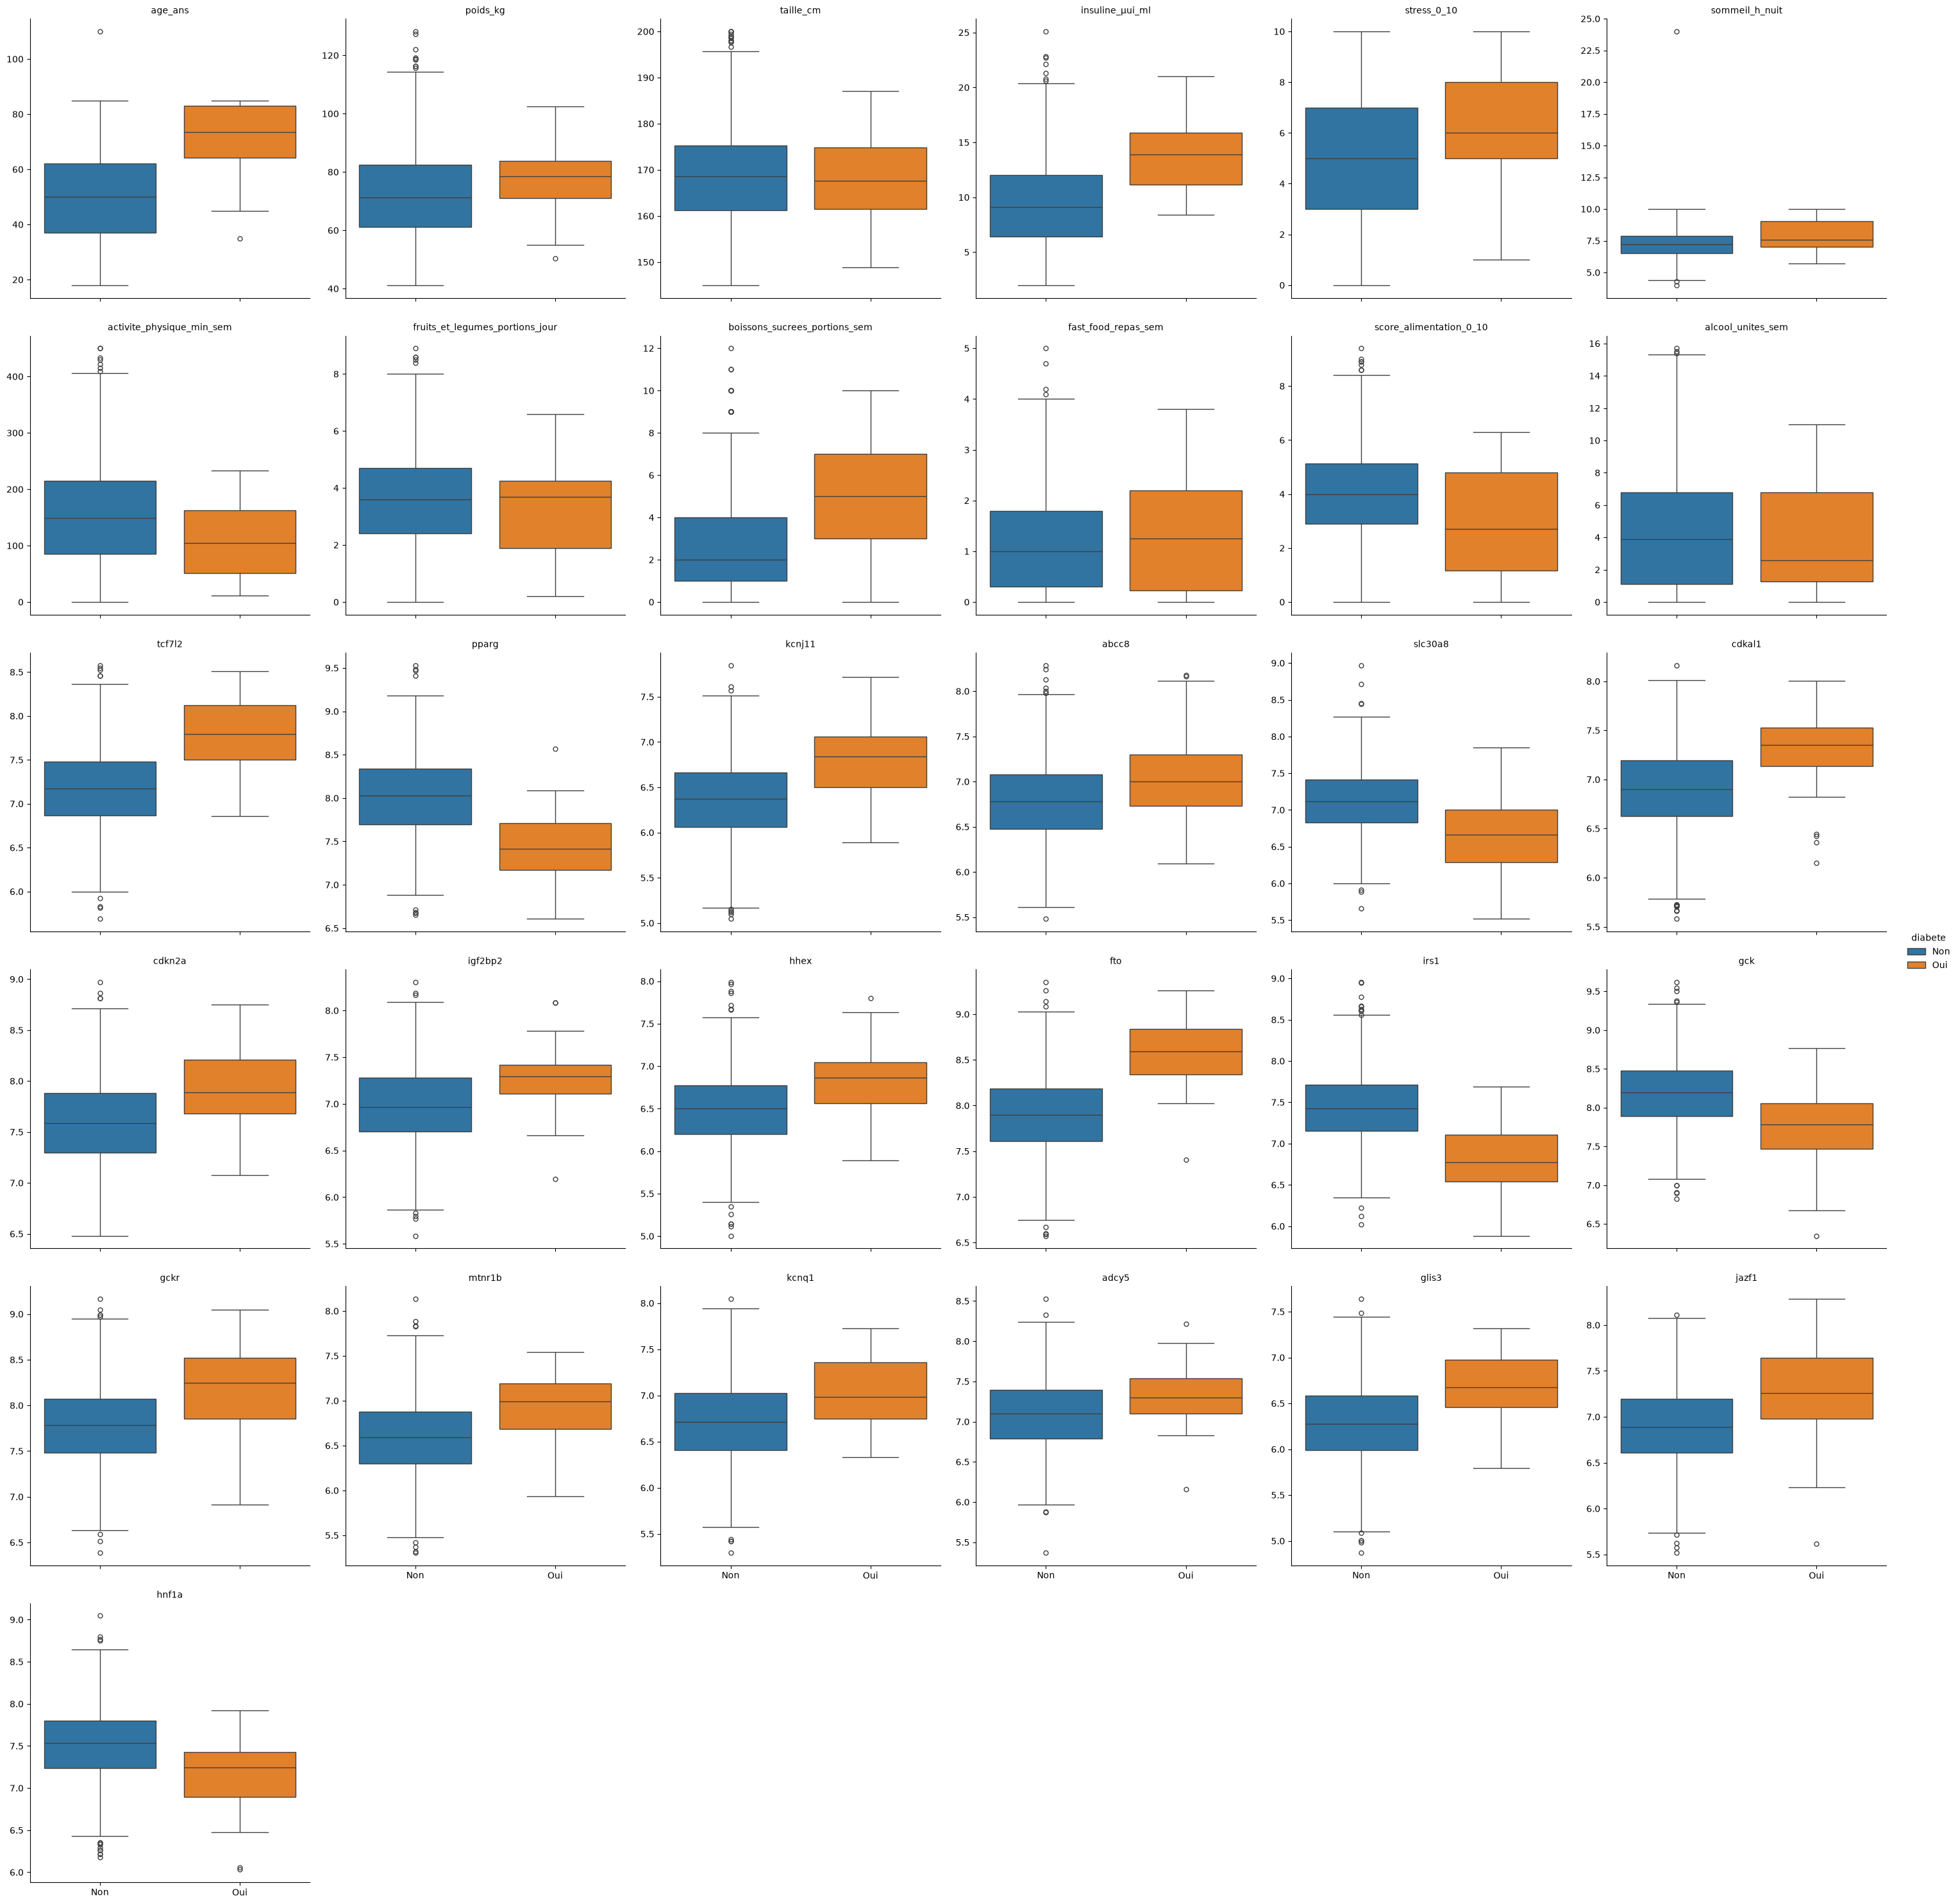

In [42]:
# colonnes numériques, sans la target
num_cols_without_target = num_cols.drop(["diabete", "diabete_type_2", "obesite", "hypertension", "maladie_cardiovasculaire"])

# On va créer un dataframe avec une ligne par patient et variable. 
# Cela nous permettra d'afficher un catplot sur nos datas en une seule fois

df_long = df_train.melt(
    id_vars="diabete",
    value_vars=num_cols_without_target,
    var_name="feature",
    value_name="value",
)
df_long["diabete"] = df_long["diabete"].map({0: "Non", 1: "Oui"})

display(df_long.shape)

g = seaborn.catplot(
    data=df_long,
    x="diabete", y="value",
    hue="diabete", legend=True,
    col="feature", col_wrap=6,
    kind="box",
    sharey=False,
    height=5,
)
g.set_titles("{col_name}")
g.set_axis_labels("", "")
plt.show()

In [43]:
df_train["diabete_type_2"].value_counts()

diabete_type_2
0    1098
1      83
2      18
3       1
Name: count, dtype: int64

### Résultats

On remarque que certaines variable on des médianes bien supérieure entre les diabètiques et les non diabètiques. On peut donc penser que certaines features seront plus utile pour la prédiction du diabète. 

On pense donc à faire de la feature selection plus tard pour réduire le nombre de feature.

A priori, L'age, l'insuline , le stress, l'activite physique, les portions de boissons sucrées par semaine, et certains gènes ont l'air d'impacter le résultat glycémique des patients. 

Nous avons déjà fait les tests d'inférence en R sur leur utilité pour expliquer la glycémie pour certaines de ces features. Ici nous sommes dans une démarche de prédiction, donc il se peut que certaines variable peu explicative puisse être utile pour la prédiction.

### Distribution

(40, 43)

(1160, 43)

/var/folders/sc/tjzc3myj4tx1c7wr1g_bnz_r0000gn/T/ipykernel_8684/1597341875.py:7: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  seaborn.distplot(positive[col])
/var/folders/sc/tjzc3myj4tx1c7wr1g_bnz_r0000gn/T/ipykernel_8684/1597341875.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  seaborn.distplot(negative[col])
/var

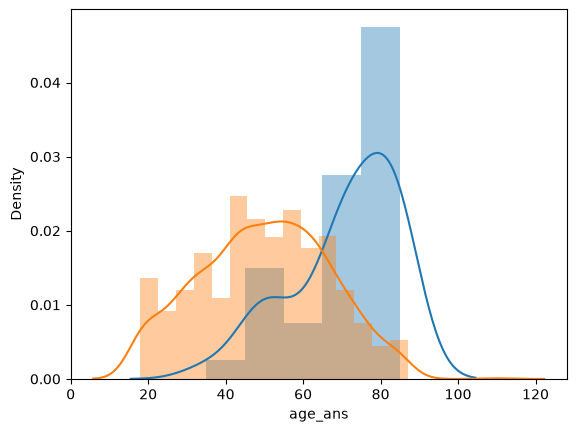

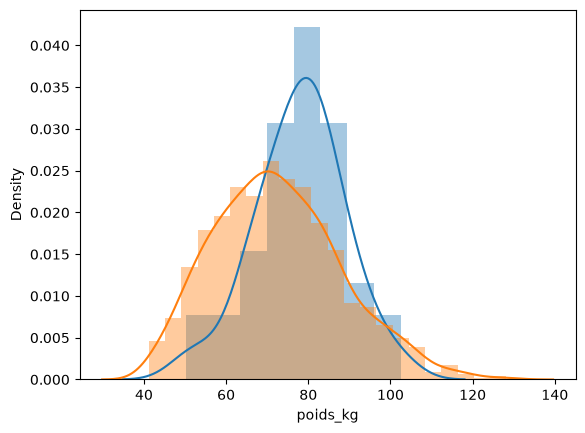

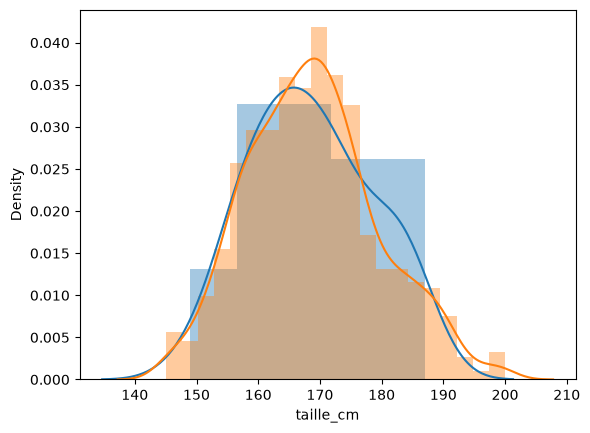

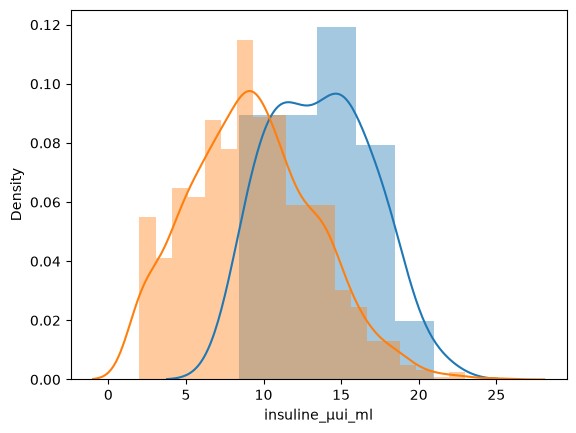

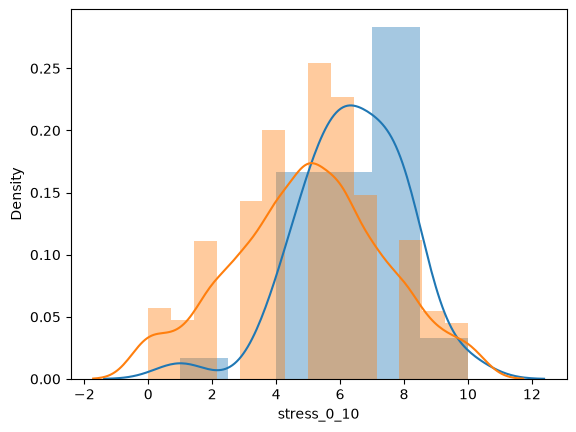

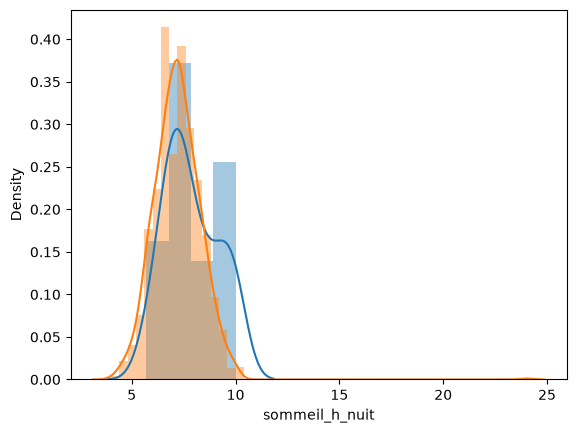

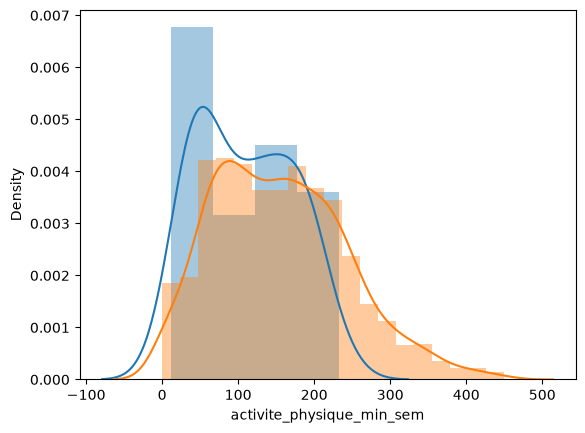

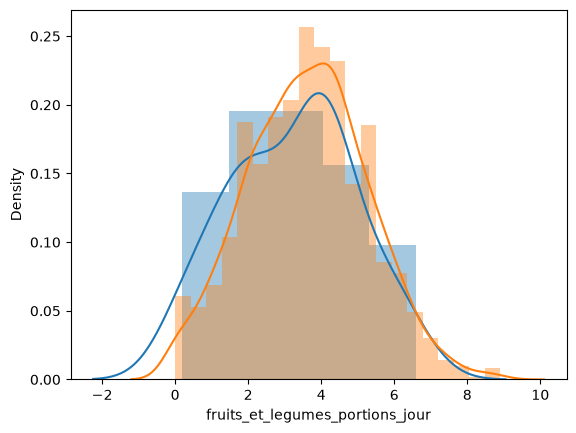

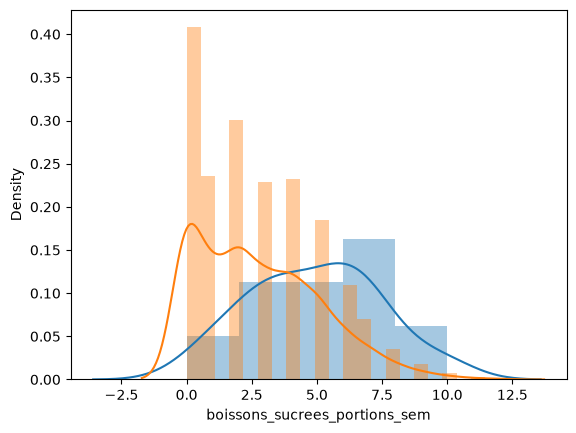

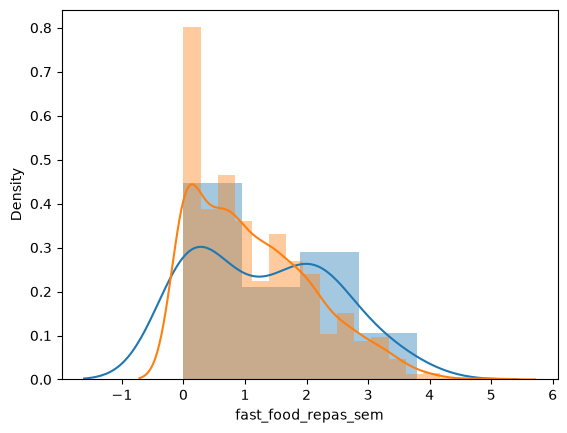

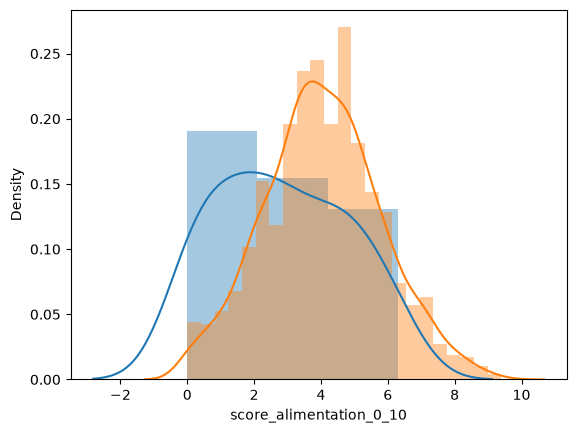

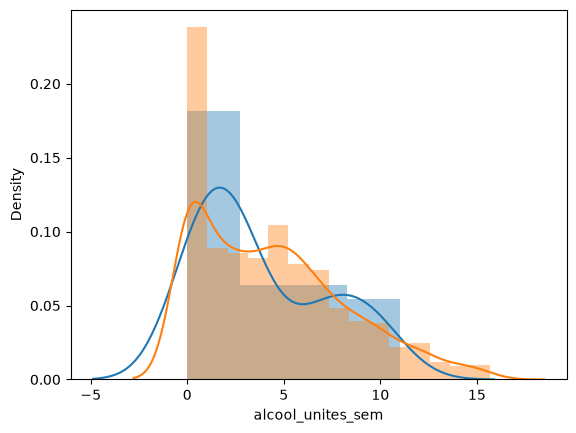

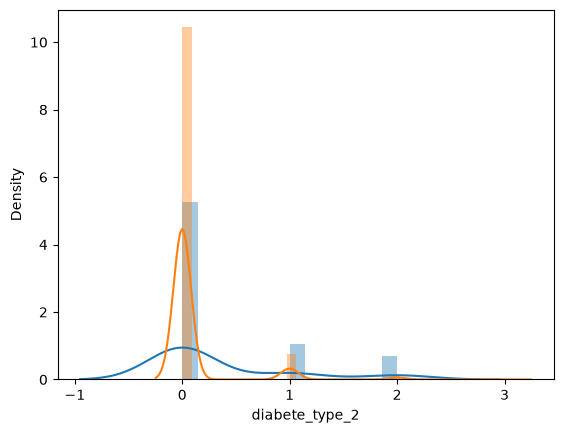

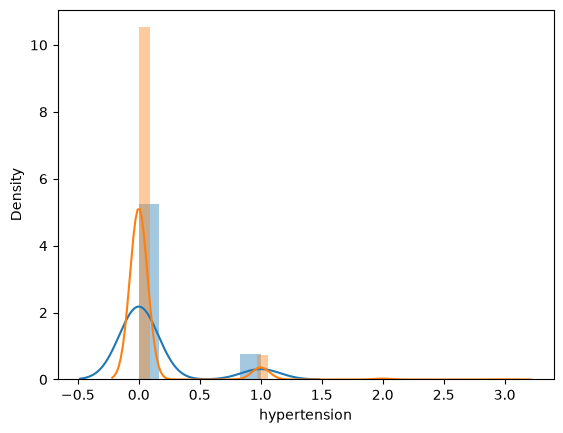

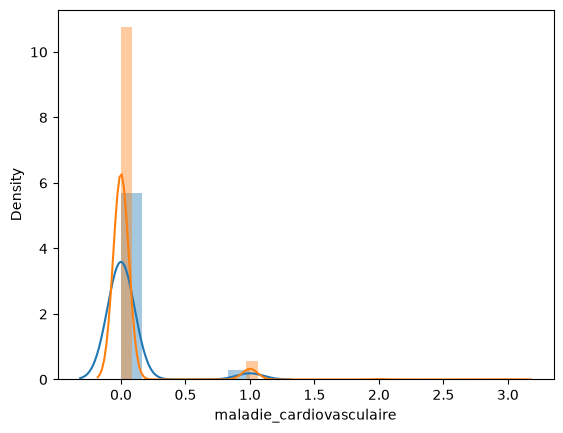

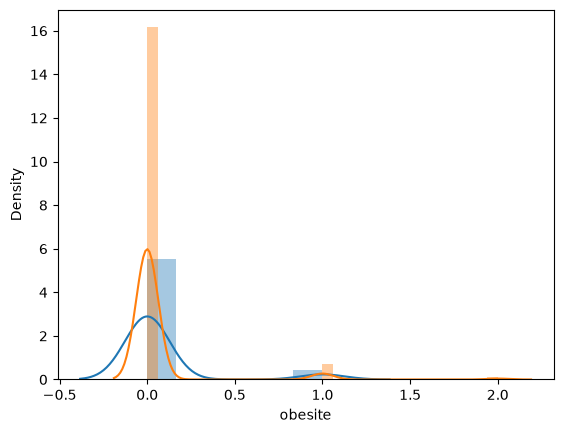

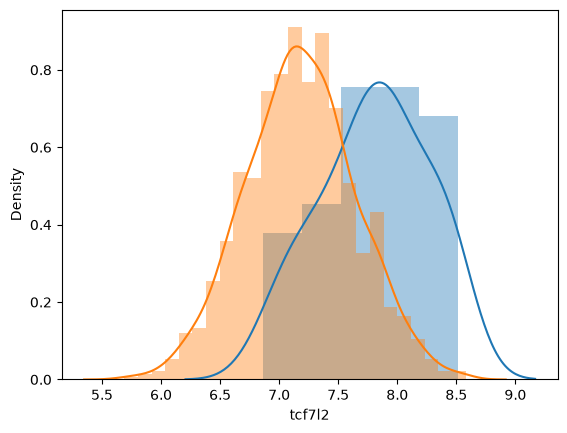

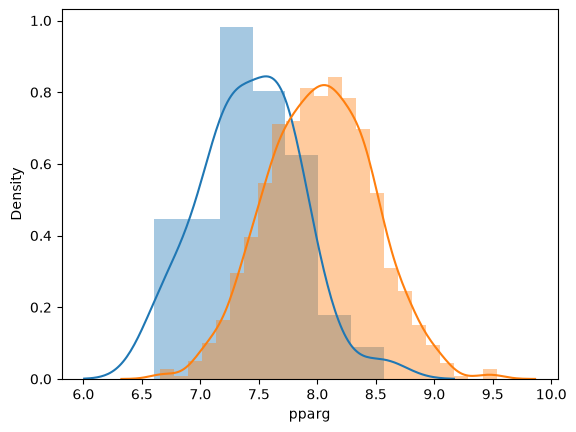

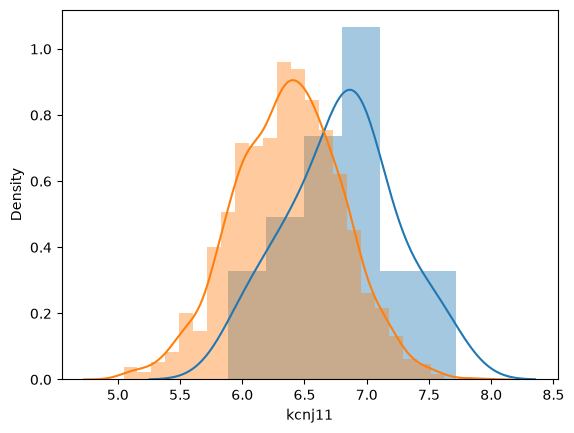

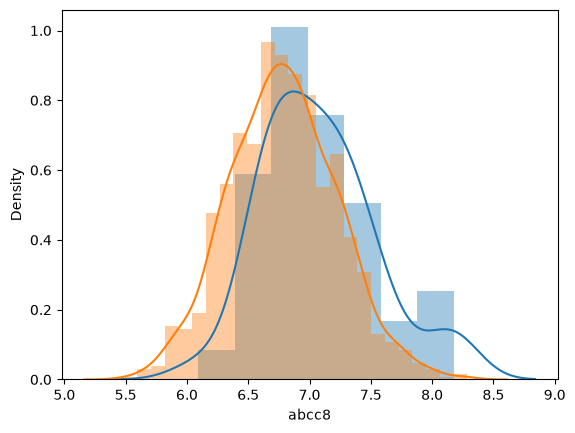

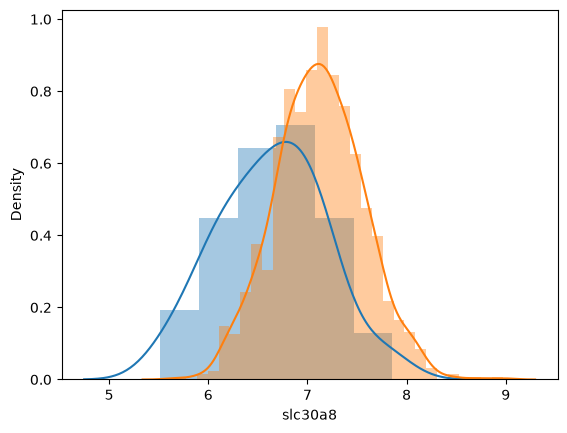

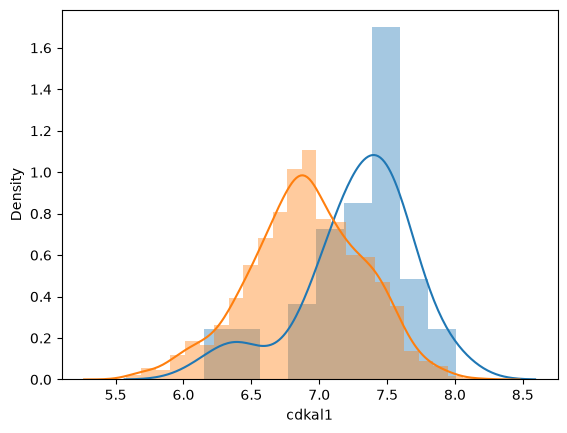

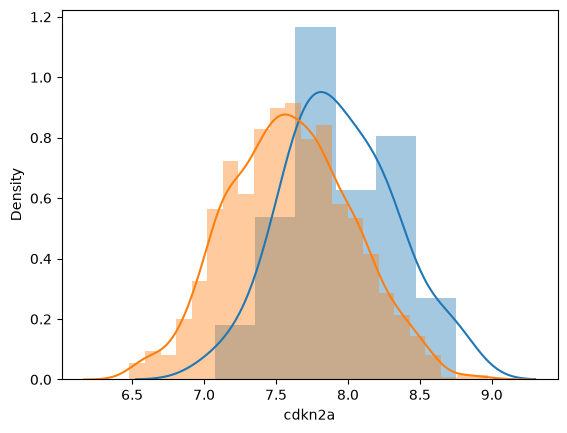

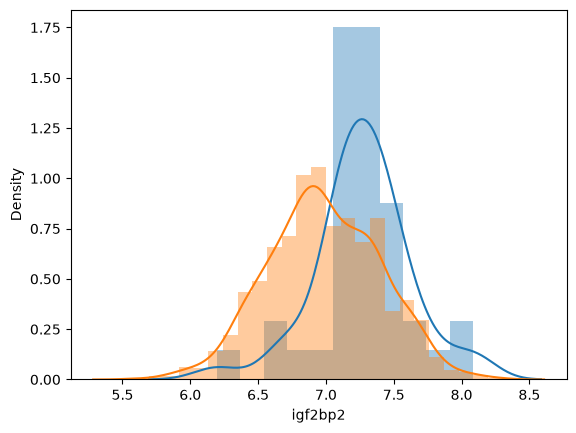

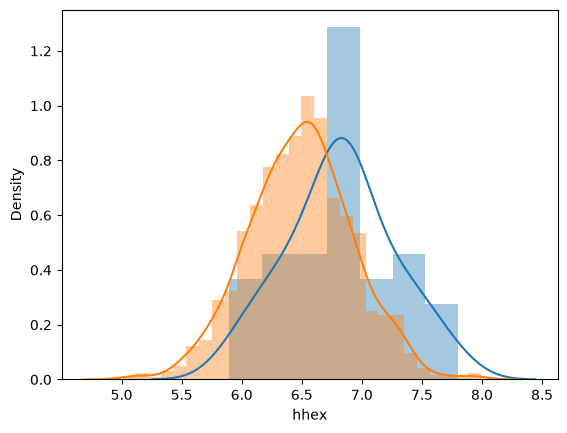

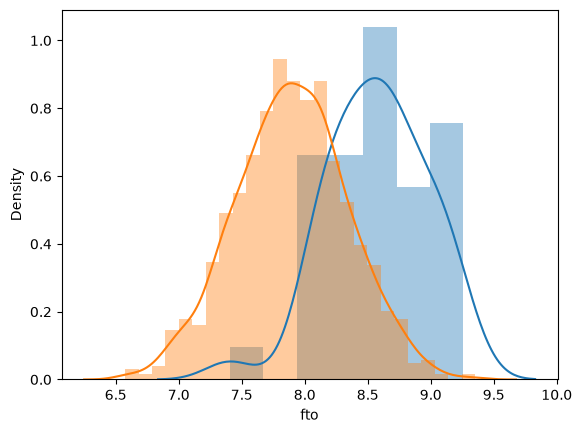

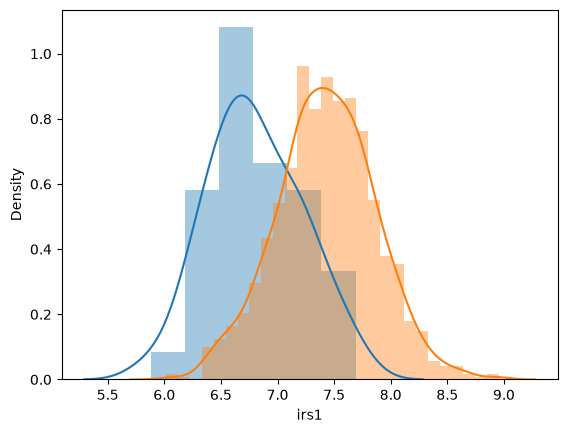

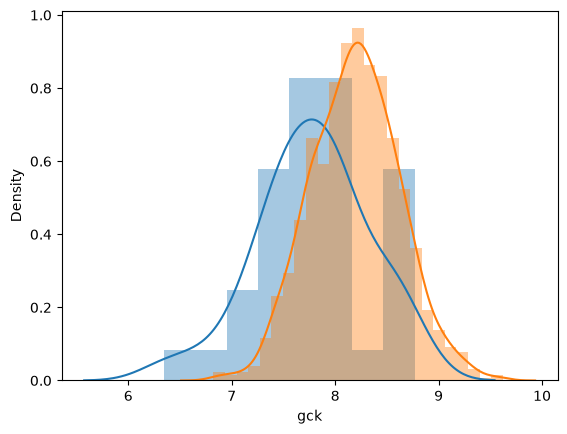

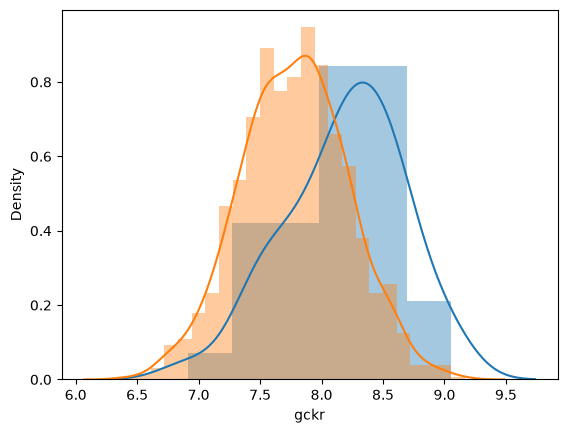

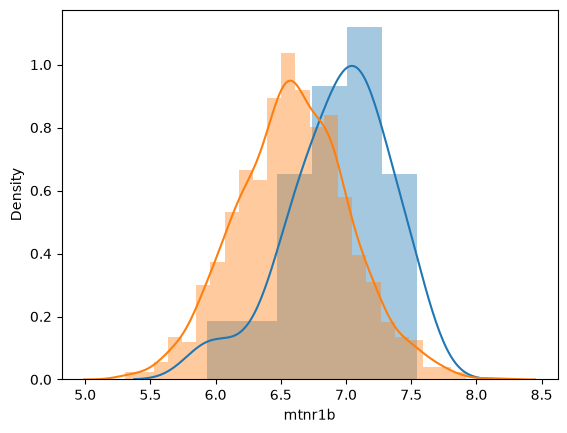

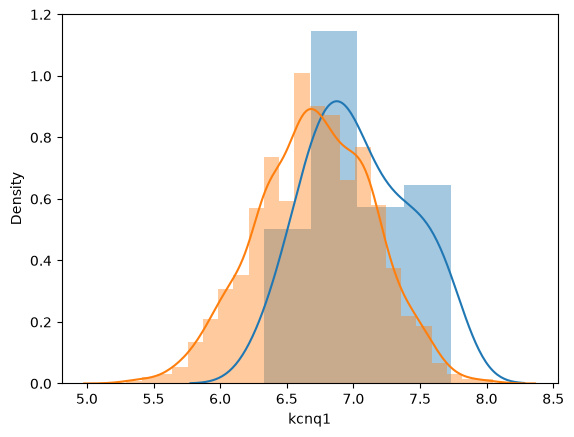

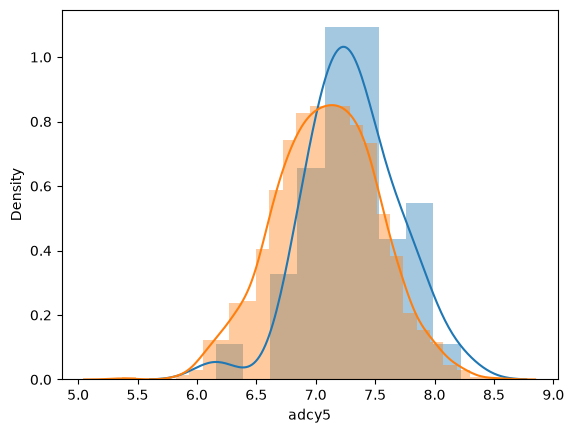

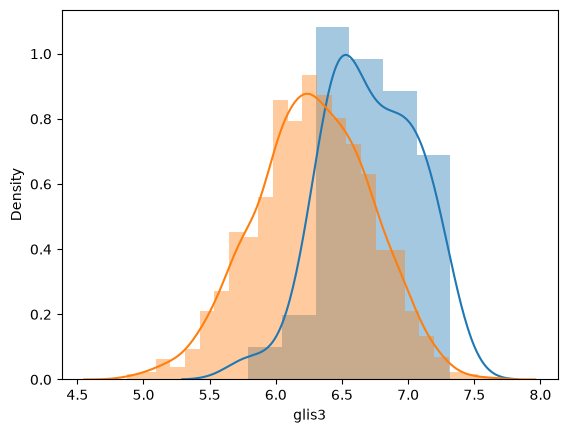

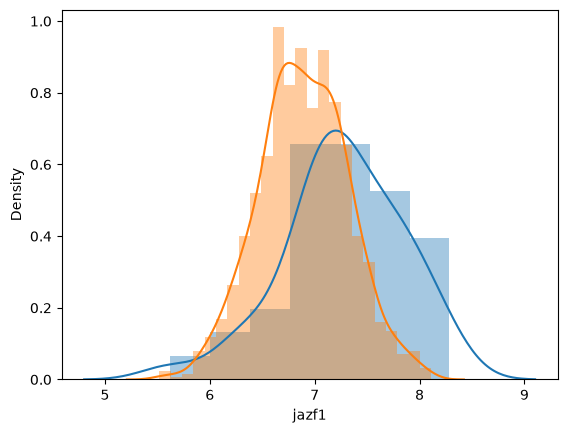

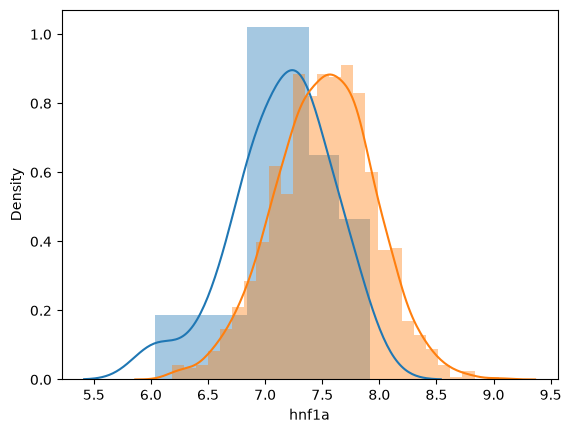

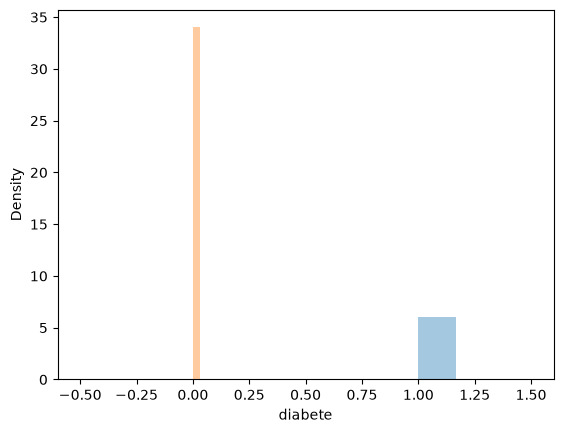

In [44]:
positive = df_train[df_train["diabete"]==1]
negative = df_train[df_train["diabete"]==0]
display(positive.shape)
display(negative.shape)
for col in df_train.select_dtypes("number"):
  plt.figure()
  seaborn.distplot(positive[col])
  seaborn.distplot(negative[col])

### Résultat

Cette analyse des distributions nous montre une différence entre celles des cas positif au diabète et celles négative. Cela nous conforte dans l'idée qu'il y a effectivement un impact de ces variables sur le diabète, ce qui pourra aider notre modèle à prédire notre target.

### Heatmap (correlation de spearman)

<Axes: xlabel='niveau_de_stress', ylabel='stress_0_10'>

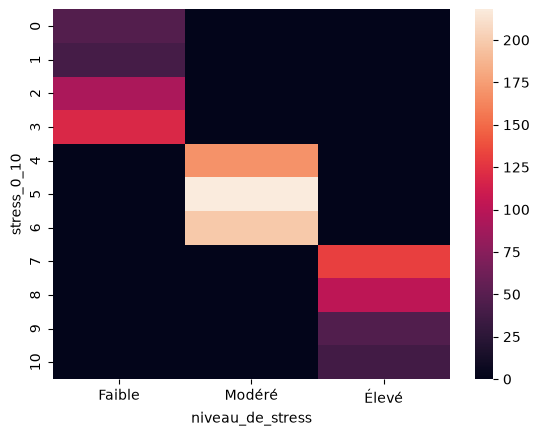

In [45]:
seaborn.heatmap(crosstab(df_train["stress_0_10"], columns=df_train["niveau_de_stress"]))

On remarque que le score de stress ou le niveau de stress communique exactement les mêmes informations. On pourra donc supprimer le plus général. Nous déciderons surement de supprimer la feature avec le moins de niveau de détail i.e. niveau_de_stress

<Axes: xlabel='niveau_dactivite', ylabel='activite_physique_min_sem'>

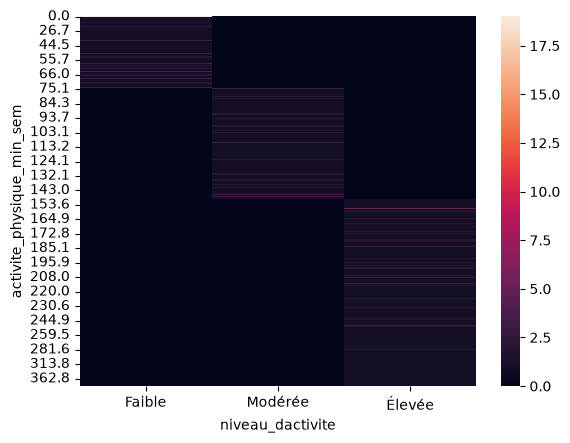

In [46]:
seaborn.heatmap(crosstab(df_train["activite_physique_min_sem"], df_train["niveau_dactivite"]))

Même remarque pour l'activité physique.

<Axes: xlabel='qualite_de_lalimentation', ylabel='score_alimentation_0_10'>

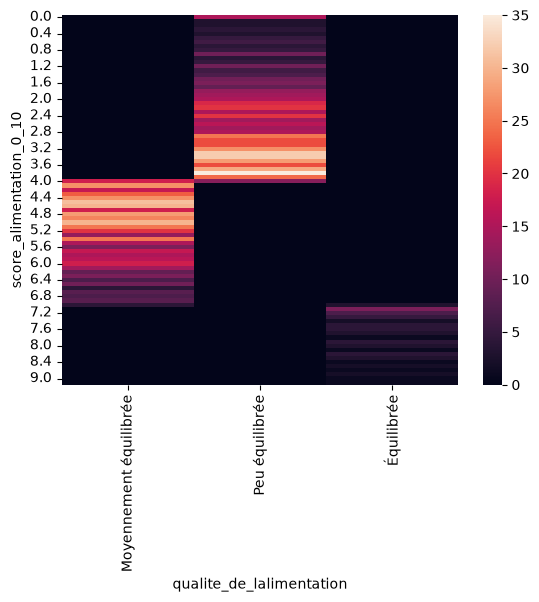

In [47]:
seaborn.heatmap(data=crosstab(df_train["score_alimentation_0_10"], df_train["qualite_de_lalimentation"]))

Même remarque.

Analysons maintenant les relations entre features.

Index(['stress_0_10', 'sommeil_h_nuit', 'activite_physique_min_sem',
       'fruits_et_legumes_portions_jour', 'boissons_sucrees_portions_sem',
       'fast_food_repas_sem', 'score_alimentation_0_10', 'alcool_unites_sem'],
      dtype='str')

<Axes: >

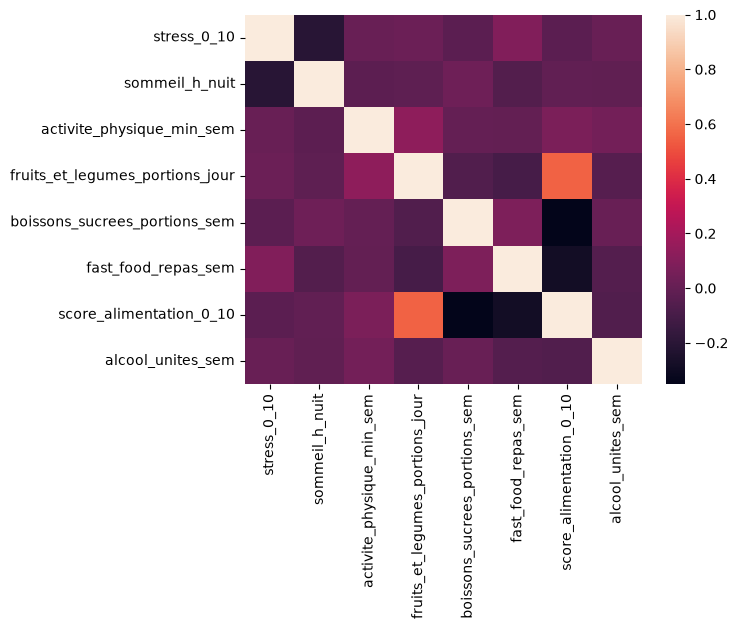

In [48]:
hygiene_num_cols = hygiene_cols.intersection(num_cols, sort=False)
display(hygiene_num_cols)

seaborn.heatmap(df_train[hygiene_num_cols].corr("spearman"))

Index(['diabete_type_2', 'hypertension', 'maladie_cardiovasculaire',
       'obesite'],
      dtype='str')

<Axes: >

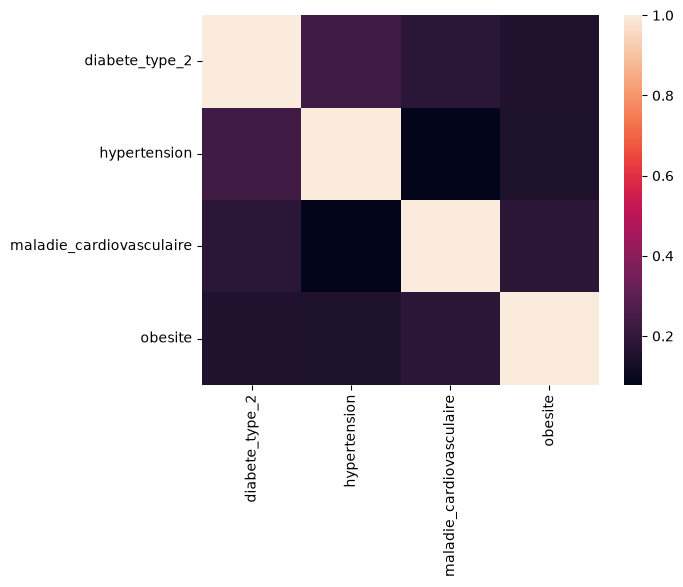

In [49]:
atcd_num_cols = atcd_cols.intersection(num_cols, sort=False)
display(atcd_num_cols)

seaborn.heatmap(df_train[atcd_num_cols].corr("spearman"))

Index(['tcf7l2', 'pparg', 'kcnj11', 'abcc8', 'slc30a8', 'cdkal1', 'cdkn2a',
       'igf2bp2', 'hhex', 'fto', 'irs1', 'gck', 'gckr', 'mtnr1b', 'kcnq1',
       'adcy5', 'glis3', 'jazf1', 'hnf1a'],
      dtype='str')

<Axes: >

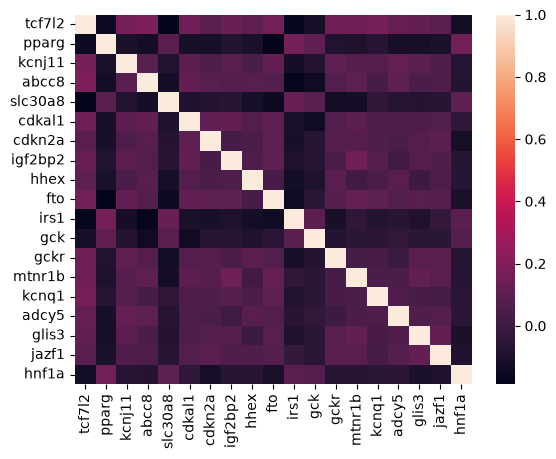

In [50]:
gene_num_cols = gene_cols.intersection(num_cols, sort=False)
display(gene_cols)

seaborn.heatmap(df_train[gene_cols].corr("spearman"))

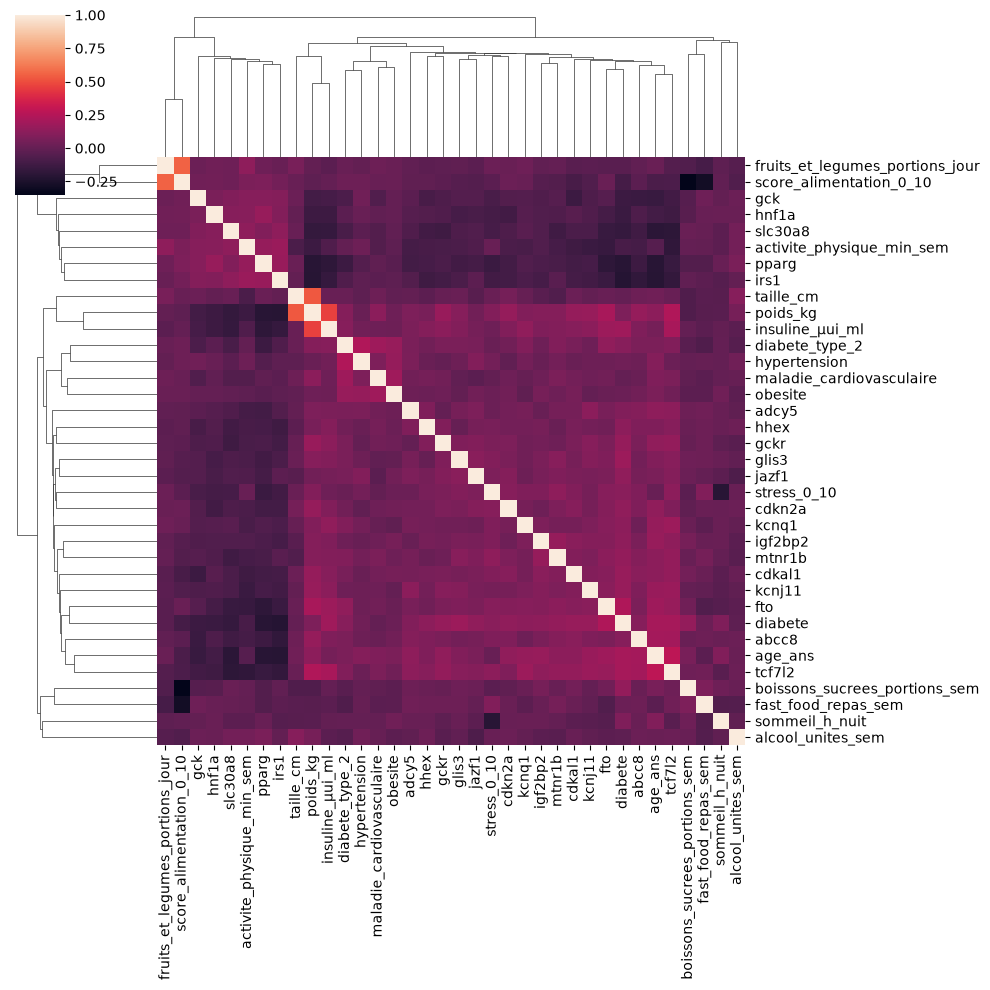

In [51]:
corr = df_train[num_cols].corr("spearman")

seaborn.clustermap(corr)
plt.show()

In [52]:
## généré par claude pour avoir les corrélation supérieure à 0.5 et ne pas devoir analyser un heatmap à la main

mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)

paires = (
    corr.where(mask)
    .stack()
    .dropna()
    .rename("spearman")
    .rename_axis(["variable_1", "variable_2"])
    .reset_index()
)
paires = paires[paires["spearman"].abs() > 0.5].sort_values("spearman", key=abs, ascending=False)
paires

,variable_1,variable_2,spearman
226,fruits_et_legumes_portions_jour,score_alimentation_0_10,0.553078
35,poids_kg,taille_cm,0.528311


On remarque que certaines variables sont un peu correlée mais que la plupart ne le sont pas. Bon signe pour notre future régression logisitique afin d'éviter la multi-colinéarité.

Par ailleurs, parmi les valeurs corrélée, on identifie le poids_kg et la taille_cm. Cela est logique et une mesure existe pour résumer les deux appelée IMC. On la remplacera donc par l'IMC afin de sauvegarder une variable.

In [53]:
df_train[["diabete", "insuline_µui_ml"]].corr("spearman")

,diabete,insuline_µui_ml
diabete,1.000000,0.185652
insuline_µui_ml,0.185652,1.000000


On peut se poser la question à propos de l'insuline. Elle pourrait être disponible au même moment que la mesure de glycémie, et donc complétement inutile dans le cadre d'une prédiction. 

On se pose la question en mesurant l'AUC entre ces variables, i.e. est-ce que l'insuline à elle seule permet de séparer les deux classes de diabète ?

In [54]:
from sklearn.metrics import roc_auc_score
roc_auc_score(df_train["diabete"], df_train["insuline_µui_ml"])

0.7985452586206896

.80 d'AUC est élevé. Mais de là à justifier un data leakage lors de l'entrainement. Pour comparer, j'analyse l'AUC de chaque variable contre notre target.

In [55]:
res = []

for col in num_cols:
  auc = roc_auc_score(df_train["diabete"], df_train[col])
  res.append((auc, col))

res.sort(reverse=True)
res

[(1.0, 'diabete'),
 (0.8757543103448275, 'fto'),
 (0.8330280172413793, 'age_ans'),
 (0.8266379310344827, 'tcf7l2'),
 (0.7985452586206896, 'insuline_µui_ml'),
 (0.7777478448275862, 'glis3'),
 (0.7560775862068966, 'kcnj11'),
 (0.7559590517241379, 'cdkal1'),
 (0.741530172413793, 'gckr'),
 (0.7394612068965516, 'mtnr1b'),
 (0.7348706896551724, 'boissons_sucrees_portions_sem'),
 (0.720635775862069, 'cdkn2a'),
 (0.7189655172413792, 'jazf1'),
 (0.7088685344827587, 'igf2bp2'),
 (0.7049137931034483, 'hhex'),
 (0.7033297413793104, 'kcnq1'),
 (0.6849030172413794, 'stress_0_10'),
 (0.6674568965517241, 'abcc8'),
 (0.6460883620689656, 'adcy5'),
 (0.6367025862068965, 'sommeil_h_nuit'),
 (0.6289116379310344, 'poids_kg'),
 (0.5876508620689654, 'diabete_type_2'),
 (0.5325538793103448, 'fast_food_repas_sem'),
 (0.5263469827586207, 'hypertension'),
 (0.5122413793103449, 'obesite'),
 (0.49907327586206895, 'maladie_cardiovasculaire'),
 (0.49538793103448275, 'taille_cm'),
 (0.4630818965517241, 'alcool_unites_

On remarque de part ces valeurs, que d'autres features ont plus de d'AUC que l'insuline. On remarque également que les gênes ainsi que l'age ont un score AUC très fort (proche de 1 ou proche de 0). Cela veut dire que ces variables seule arrive à bien séparer les cas positifs des cas négatifs. On ne prendra aucune décision concernant les variables avec un AUC de 0.5 car le faible nombre de données, le hasard ou simplement le fait qu'elles sont évaluées seule fait que nous ne pouvons pas être certains de leur importance dans un futur modèle de machine learning. Ces valeurs AUC sont là à titre informatif seulement. 

### Analyse des features par rapport à la target

#### Cat vs target

,effectif,positifs,taux_pct
sexe,,,
F,741,20,2.7
M,454,20,4.4
Unknown,5,0,0.0


,effectif,positifs,taux_pct
groupe_sanguin,,,
A+,351,12,3.4
A-,42,1,2.4
AB+,81,3,3.7
AB-,22,0,0.0
B+,154,4,2.6
B-,12,0,0.0
O+,470,12,2.6
O-,68,8,11.8


,effectif,positifs,taux_pct
corticoides,,,
Non,1100,34,3.1
Oui,100,6,6.0


,effectif,positifs,taux_pct
niveau_de_stress,,,
Faible,298,1,0.3
Modéré,585,20,3.4
Élevé,317,19,6.0


,effectif,positifs,taux_pct
niveau_dactivite,,,
Faible,252,16,6.3
Modérée,357,11,3.1
Élevée,591,13,2.2


,effectif,positifs,taux_pct
qualite_de_lalimentation,,,
Moyennement équilibrée,532,12,2.3
Peu équilibrée,605,28,4.6
Équilibrée,63,0,0.0


,effectif,positifs,taux_pct
tabagisme,,,
Non,976,36,3.7
Oui,224,4,1.8


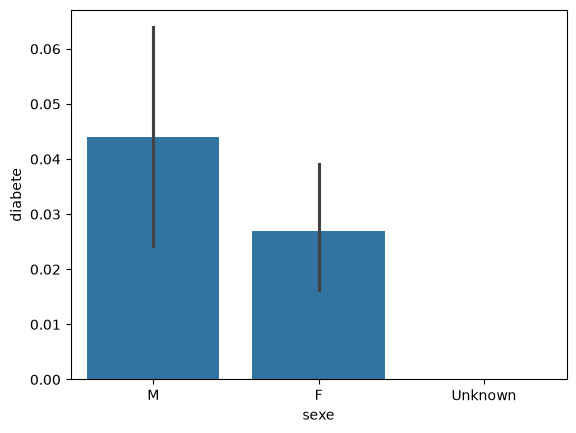

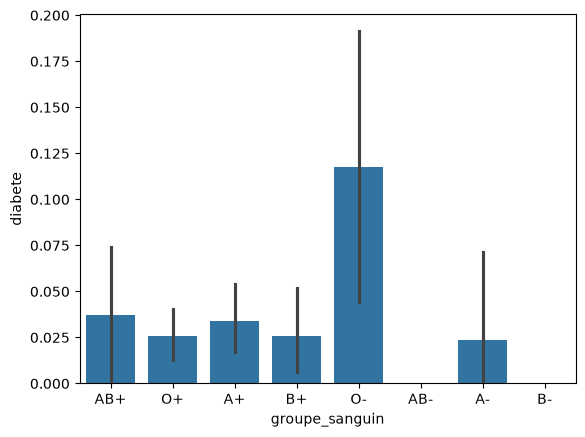

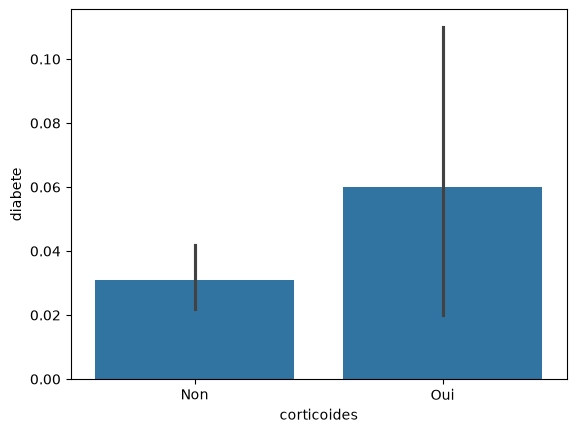

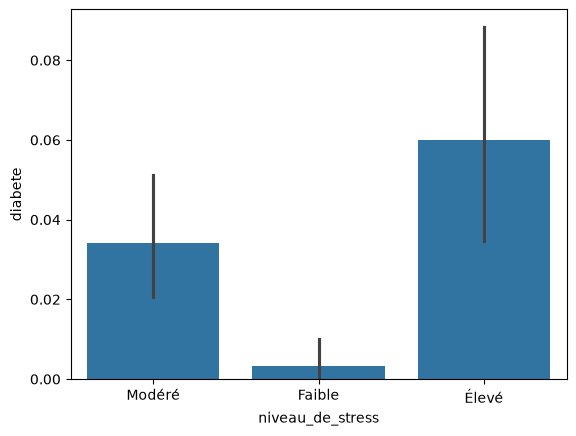

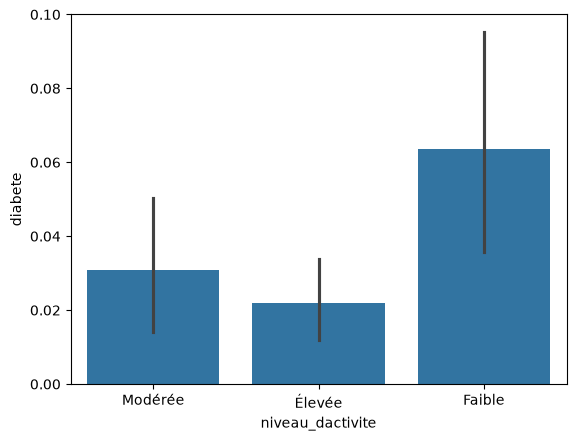

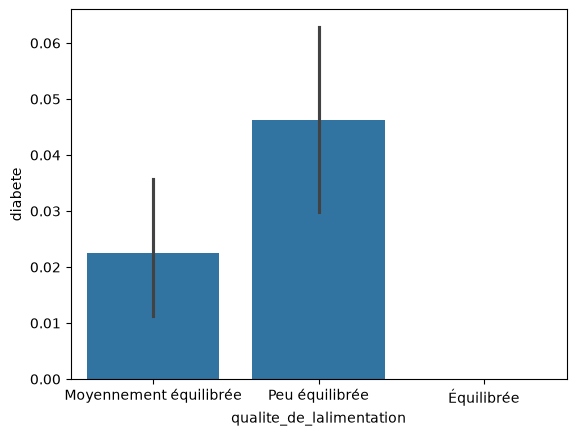

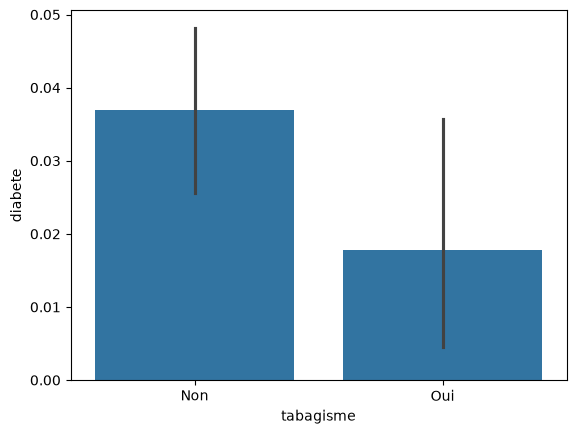

In [56]:
for col in cat_cols:
  plt.figure()
  display(df_train.groupby(col)["diabete"].agg(
    effectif="count",
    positifs="sum",
    taux_pct=lambda s: round(s.mean() * 100, 1),
  ))
  
  seaborn.barplot(data=df_train, x=col, y="diabete")

## 8. Pre-processing

In [57]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler,OneHotEncoder,FunctionTransformer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif

### Création et suppression de features

In [58]:
def feature_engineering(X):
  res = X.copy()
  res["imc"] = X["poids_kg"] / (X["taille_cm"] / 100) ** 2
  return res.drop(columns=["poids_kg", "taille_cm", "niveau_de_stress", "niveau_dactivite", "qualite_de_lalimentation"])

In [59]:
def feature_selection(X):
  selector = VarianceThreshold(0.2)
  selector.fit_transform(X)
  return X[X.columns[selector.get_support()]]

### Création de la pipeline de pre-processing

In [60]:
num_selector = make_column_selector(dtype_include="number")
cat_selector = make_column_selector(dtype_exclude="number")
prep = ColumnTransformer([
  ("num", StandardScaler(), num_selector), 
  ("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat_selector)
  ], verbose_feature_names_out=False).set_output(transform="pandas")

In [61]:
preprocessor = Pipeline([
  ("feature_engineering", FunctionTransformer(feature_engineering)),
  ("prep", prep),
])

In [62]:
preprocessor

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('prep', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fea...t 0x1776cff60>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDicti

Analysons la sortie d'un tel preprocessor

In [63]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

In [64]:
X_train_prep.shape

(1200, 47)

In [65]:
X_train_prep.shape

(1200, 47)

On remarque que malgré nos efforts, nous avons toujours 47 features. Nous verrons plus tard si cela impacte négativement nos modèles en appliquant des selections de feature.

In [66]:
prep_num_cols = X_train_prep.select_dtypes("number").columns.to_list()
prep_cat_cols = X_train_prep.select_dtypes("str").columns.to_list()

## 9. Creation des Modèles

### Pipeline finale avec modèle

In [67]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix, precision_recall_curve, roc_curve, classification_report
from xgboost import XGBClassifier

In [68]:
scores = {"f1":f1_score, "recall":recall_score, "precision":precision_score, "accuracy":accuracy_score}

### Regression Logistique

Vu depuis https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.LogisticRegression.html#:~:text=l1_ratio,-float%2C%20default%3D0.0
On utilise un autre solver que celui par défaut pour pouvoir jouer avec le paramètre l1_ratio (switcher sur une régularization l1 et l2). On testera ces paramètres avec un GridSearchCV.

### Cross Validation

In [69]:
from sklearn.model_selection import validation_curve, GridSearchCV, StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_val_predict, cross_validate

On utilise une StratifiedKFold pour garder la même proportion de classe positive (la classe avec le moins d'occurrence du dataset) dans le train set et le validation set

In [70]:
stra_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Test simple sur une regression avec la repartition des classes équilibrées ou non.

In [71]:
reg_pipe_simple = Pipeline([
  ("preprocessor", preprocessor),
  # ("feature_selection", SelectKBest(score_func=f_classif, k=15)),
  ("regression", LogisticRegression())
  ]
)

In [72]:
reg_class_weight_range = [None, "balanced"]
reg_simple_train_score, reg_simple_val_score = (
  validation_curve(
    reg_pipe_simple, 
    X_train, 
    y_train, 
    param_name="regression__class_weight", 
    param_range=reg_class_weight_range, 
    cv=stra_cv, 
    scoring="roc_auc"
  )
)

In [73]:
DataFrame({
    "class_weight": reg_class_weight_range,
    "train": reg_simple_train_score.mean(axis=1),
    "validation": reg_simple_val_score.mean(axis=1),
    "diff": reg_simple_val_score.mean(axis=1) - reg_simple_train_score.mean(axis=1)
})

,class_weight,train,validation,diff
0,NaN,0.999111,0.980711,-0.018400
1,balanced,0.999428,0.977694,-0.021734


On ne voit pas beaucoup de différence. On fait un test plus avancé avec un GridSearchCV.

In [74]:
reg_pipe = Pipeline([
  ("preprocessor", preprocessor),
  # ("feature_selection", SelectKBest(score_func=f_classif, k=20)),
  ("regression", LogisticRegression(solver="liblinear"))
  ]
)

In [75]:
reg_pipe_simple

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('prep', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fea...t 0x1776cff60>

On décide donc de tester les deux regularization L1/L2 via un ratio l1_ratio entre 0(L2) et 1 (L1) ainsi que la force C. De plus, nous testerons un ensemble balanced et non balanced

In [76]:
reg_param_grid = {
  "regression__C": np.logspace(-3, 5, 30),
  "regression__l1_ratio": [0,1],
  "preprocessor__prep__cat__drop": [None, "if_binary"]
}
reg_grid = GridSearchCV(reg_pipe, reg_param_grid, scoring="roc_auc", cv=stra_cv, return_train_score=True)

In [77]:
reg_grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'preprocessor__prep__cat__drop': [None, 'if_binary'], 'regression__C': array([1.0000...00000000e+05]), 'regression__l1_ratio': [0, 1]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_p

In [78]:
print(reg_grid.best_params_)
reg_best = reg_grid.best_estimator_

{'preprocessor__prep__cat__drop': None, 'regression__C': np.float64(0.08531678524172806), 'regression__l1_ratio': 0}


In [79]:
print(f'AUC moyenne en CV : {reg_grid.best_score_:.4f}')

AUC moyenne en CV : 0.9837


In [80]:
# sur base de https://scikit-learn.org/1.9/auto_examples/model_selection/plot_grid_search_stats.html#sphx-glr-auto-examples-model-selection-plot-grid-search-stats-py

reg_results_df = DataFrame(reg_grid.cv_results_)
reg_results_df = reg_results_df.sort_values(by=["rank_test_score"])
reg_results_df = reg_results_df.set_index(
    reg_results_df["params"].apply(lambda x: "_".join(str(val) for val in x.values()))
).rename_axis("kernel")
reg_results_df[["params", "rank_test_score", "mean_test_score", "std_test_score"]]

,params,rank_test_score,mean_test_score,std_test_score
kernel,,,,
None_0.08531678524172806_0,"{'preprocessor__prep__cat__drop': None, 'regre...",1,0.983728,0.014575
None_0.16102620275609392_0,"{'preprocessor__prep__cat__drop': None, 'regre...",2,0.983621,0.014151
None_0.3039195382313198_0,"{'preprocessor__prep__cat__drop': None, 'regre...",3,0.983190,0.014415
if_binary_0.3039195382313198_0,"{'preprocessor__prep__cat__drop': 'if_binary',...",4,0.982866,0.012847
None_0.04520353656360243_0,"{'preprocessor__prep__cat__drop': None, 'regre...",5,0.982759,0.015932
...,...,...,...,...
None_0.0018873918221350976_1,"{'preprocessor__prep__cat__drop': None, 'regre...",111,0.500000,0.000000
if_binary_0.006723357536499335_1,"{'preprocessor__prep__cat__drop': 'if_binary',...",111,0.500000,0.000000
if_binary_0.01268961003167922_1,"{'preprocessor__prep__cat__drop': 'if_binary',...",111,0.500000,0.000000


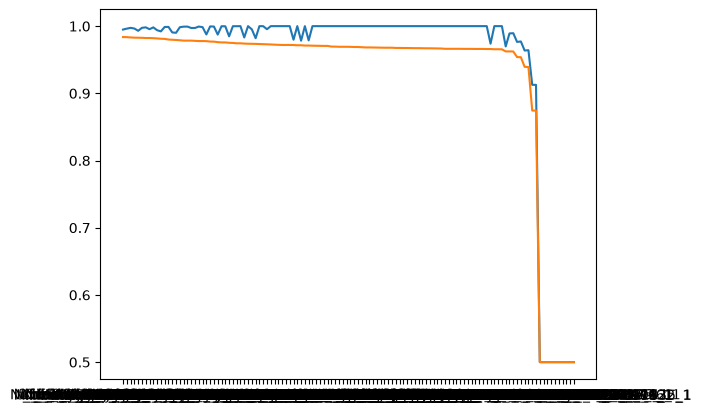

In [81]:
plt.plot(reg_results_df["mean_train_score"])
plt.plot(reg_results_df["mean_test_score"])

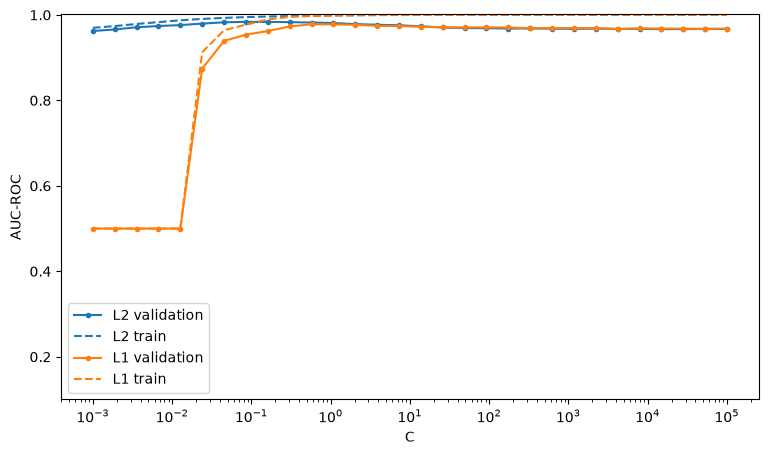

In [82]:
# https://scikit-learn.org/stable/auto_examples/linear_model/plot_logistic_path.html

reg_cv_results = DataFrame(reg_grid.cv_results_)
reg_cv_results = reg_cv_results[reg_cv_results["param_preprocessor__prep__cat__drop"].isna()]

_, ax = plt.subplots(figsize=(9, 5))
for l1, nom in [(0, "L2"), (1, "L1")]:
    d = reg_cv_results[reg_cv_results["param_regression__l1_ratio"] == l1].sort_values("param_regression__C")
    ligne, = ax.semilogx(d["param_regression__C"], d["mean_test_score"], "o-", ms=3, label=f"{nom} validation")
    ax.semilogx(d["param_regression__C"], d["mean_train_score"], "--", color=ligne.get_color(), label=f"{nom} train")

ax.set_xlabel("C")
ax.set_ylabel("AUC-ROC")
ax.set_ylim(0.1, 1.001)
ax.legend()
plt.show()

/Users/ismail/workspace/formation@data/common_core/applications/01_integrated_project/python/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/Users/ismail/workspace/formation@data/common_core/applications/01_integrated_project/python/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
  File "/Users/ismail/workspace/formation@data/common_core/applications/01_integrated_project/python/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py", line 80, in inner_f
    return f(*args, **kwargs)
  File "/Users/ismail/workspace/formation@data/common_core/applications/01_integrated_project/python/.venv/lib/python3.13/site-packages/sklearn/metrics/_scorer.py", line 328, in __call__
    return 

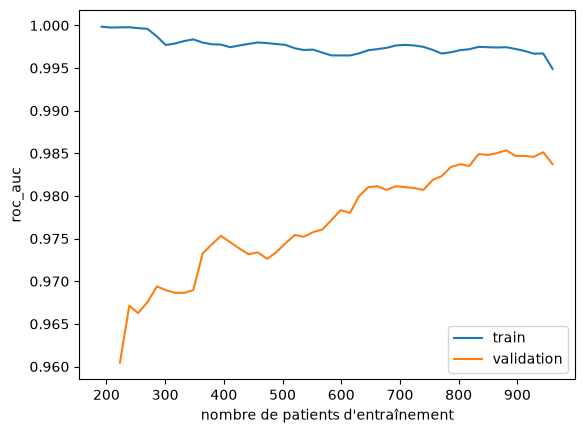

In [83]:
from sklearn.model_selection import learning_curve

reg_learning_sizes, reg_learning_train_score, reg_learning_val_score = learning_curve(
    reg_best, X_train, y_train,
    train_sizes=np.linspace(0.2, 1.0, 50),
    cv=stra_cv,
    scoring="roc_auc",
)

plt.plot(reg_learning_sizes, reg_learning_train_score.mean(axis=1), label="train")
plt.plot(reg_learning_sizes, reg_learning_val_score.mean(axis=1), label="validation")
plt.xlabel(xlabel="nombre de patients d'entraînement")
plt.ylabel("roc_auc")
plt.legend()
plt.show()

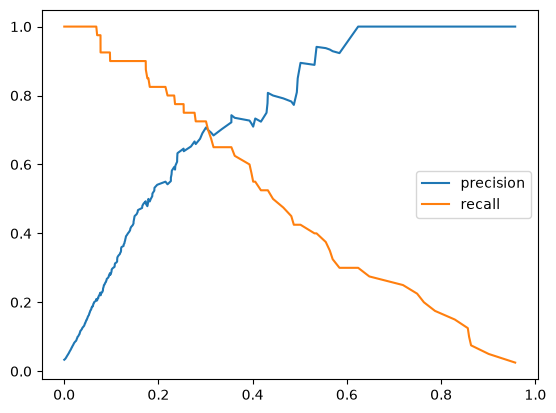

In [84]:
reg_cv_proba = cross_val_predict(reg_best, X_train, y_train, cv=stra_cv, method="predict_proba")[:, 1]
reg_precision, reg_recall, reg_threshold = precision_recall_curve(y_train, reg_cv_proba)
plt.plot(reg_threshold, reg_precision[:-1])
plt.plot(reg_threshold, reg_recall[:-1])
plt.legend(["precision", "recall"])
plt.show()

In [85]:
threshold_index = np.where(reg_recall == 0.8)

In [86]:
threshold_index[0][-1]

np.int64(1146)

In [87]:
print(f"recall {reg_recall[:-1][threshold_index[0][-1]]}")
print(f"precision {reg_precision[:-1][threshold_index[0][-1]]}")
print(f"threshold {reg_threshold[:-1][threshold_index[0][-1]]}")

recall 0.8
precision 0.5925925925925926
threshold 0.23354788199279752


### Remarque

Ce GridSearchCV nous indique qu'en réalité, l'impact d'un régularization est assez négligeable. Les meilleurs score sont atteint aux alentours de [0.5, 1] Il faudrait faire un test statistique pour en être convaincu, mais les différence entre les scores moyens de 3 premiers meilleurs modèles se joue à 0.001 alor que l'écart type est d'environ 0.01. On ne peut donc probablement pas interpréter ces différences comme étant significatives. 

De plus avec les courbes de train et de validation sur une L1/L2, on remarque plusieurs choses : 

- La regularization L1 qui supprime des variables impact très négativement le score quand elle a un score C petit (c'est à dire un fort impact). Cela contre-dit notre théorie sur le trop de variable. 
- La regularization L2 est assez efficace, on remarque qu'on atteint le max pour le validation set avec `C = 0.573`. C'est un impact moyen-fort. 
- La regularization L2 qui fonctionne bien démontre aussi que presque toutes les variables sont utiles et apporte leur lot d'information pour la prédiction. C'est d'ailleurs pour cette raison que la L1 impact aussi négativement le score du validation set.
- Il y a au final peu d'overfitting avec notre modèle. L'écart entre les scores AUC-ROC du train set et validation set ne s'éloignent beaucoup. De plus, ajouter des patients améliore le score du validation test. S'il y avait un cas d'overfitting, on se serait plutôt attendu à voir le score du validation test baisser à force d'ajouter de nouveaux patients sur lesquels le modèle aurait pu mieux se fitter.

De plus on observe que sur la CV on a un AUC moyen de 0.98. Ce score ne dépend d'aucun threshold et est excellent. Dans le cas d'une prédiction dans le cadre du diagnostic du diabète (ou du moins d'une glycémie élevée), ce qui va réellement nous intéressé est le recall, c'est à dire le ratio de patient correctement classé avec une glycémie elevée parmi tous ceux classé avec une glycémie elevée. En effet, on préfère souvent des fausses alertes, c'est à dire une précision basse, que des cas de glycémie élevée manquées.

C'est pourquoi nous avons analysé la courbe precision/recall et trouvé que le meilleur threshold pour optimiser le recal se trouvait aux alentours de 0.2. 

Dans la pratique ce threshold devrait être adapté en fonciton des réels résultat voulu par le métier. Dans notre cas nous laisseront le threshold par défaut du modèle.

In [88]:
reg_y_pred = reg_grid.predict(X_test)
reg_y_proba = reg_grid.predict_proba(X_test)[:,1]

In [89]:
reg_y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

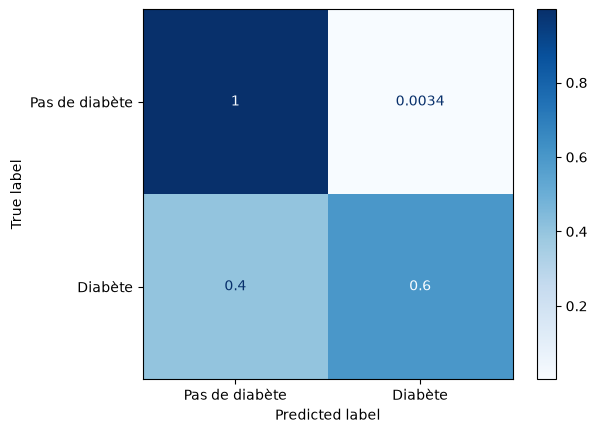

In [90]:
ConfusionMatrixDisplay.from_predictions(y_test,
    reg_y_pred,
    display_labels=['Pas de diabète', 'Diabète'],
    cmap='Blues',
    normalize="true"
    )

In [91]:
recall_score(y_test, reg_y_pred)

0.6

In [92]:
precision_score(y_test, reg_y_pred)

0.8571428571428571

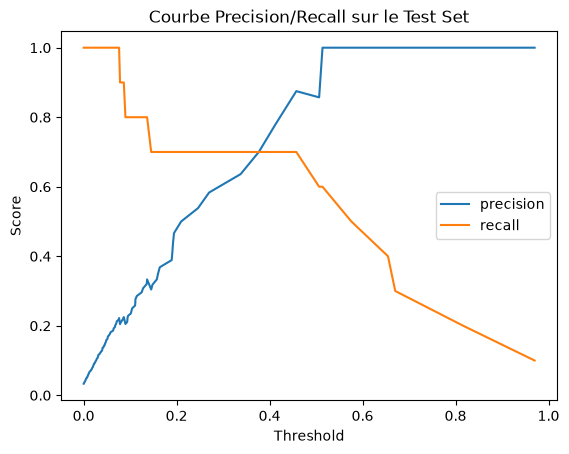

In [93]:
reg_test_precision, reg_test_recall, reg_test_threshold = precision_recall_curve(y_test, reg_y_proba)
plt.plot(reg_test_threshold, reg_test_precision[:-1])
plt.plot(reg_test_threshold, reg_test_recall[:-1])
plt.legend(["precision", "recall"])
plt.title("Courbe Precision/Recall sur le Test Set")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.show()

In [94]:
reg_y_proba = reg_grid.predict_proba(X_test)[:,1]

In [95]:
roc_auc_score(y_test,reg_y_proba)

0.9713793103448276

#### Comprendre les coefficients de la régression logistique

,coefficient_standardise,coefficient_par_unite,odds_ratio_par_unite,sens
variable,,,,
corticoides_Non,-1.0162,-1.0162,0.3620,vers glycémie non élevée
tabagisme_Non,-0.8538,-0.8538,0.4258,vers glycémie non élevée
sexe_F,-0.8497,-0.8497,0.4276,vers glycémie non élevée
groupe_sanguin_O+,-0.5938,-0.5938,0.5522,vers glycémie non élevée
tabagisme_Oui,-0.5513,-0.5513,0.5762,vers glycémie non élevée
sexe_M,-0.5182,-0.5182,0.5956,vers glycémie non élevée
fto,0.4155,0.9066,2.4759,vers glycémie élevée
imc,-0.4118,-0.0924,0.9118,vers glycémie non élevée
irs1,-0.3909,-0.8693,0.4192,vers glycémie non élevée


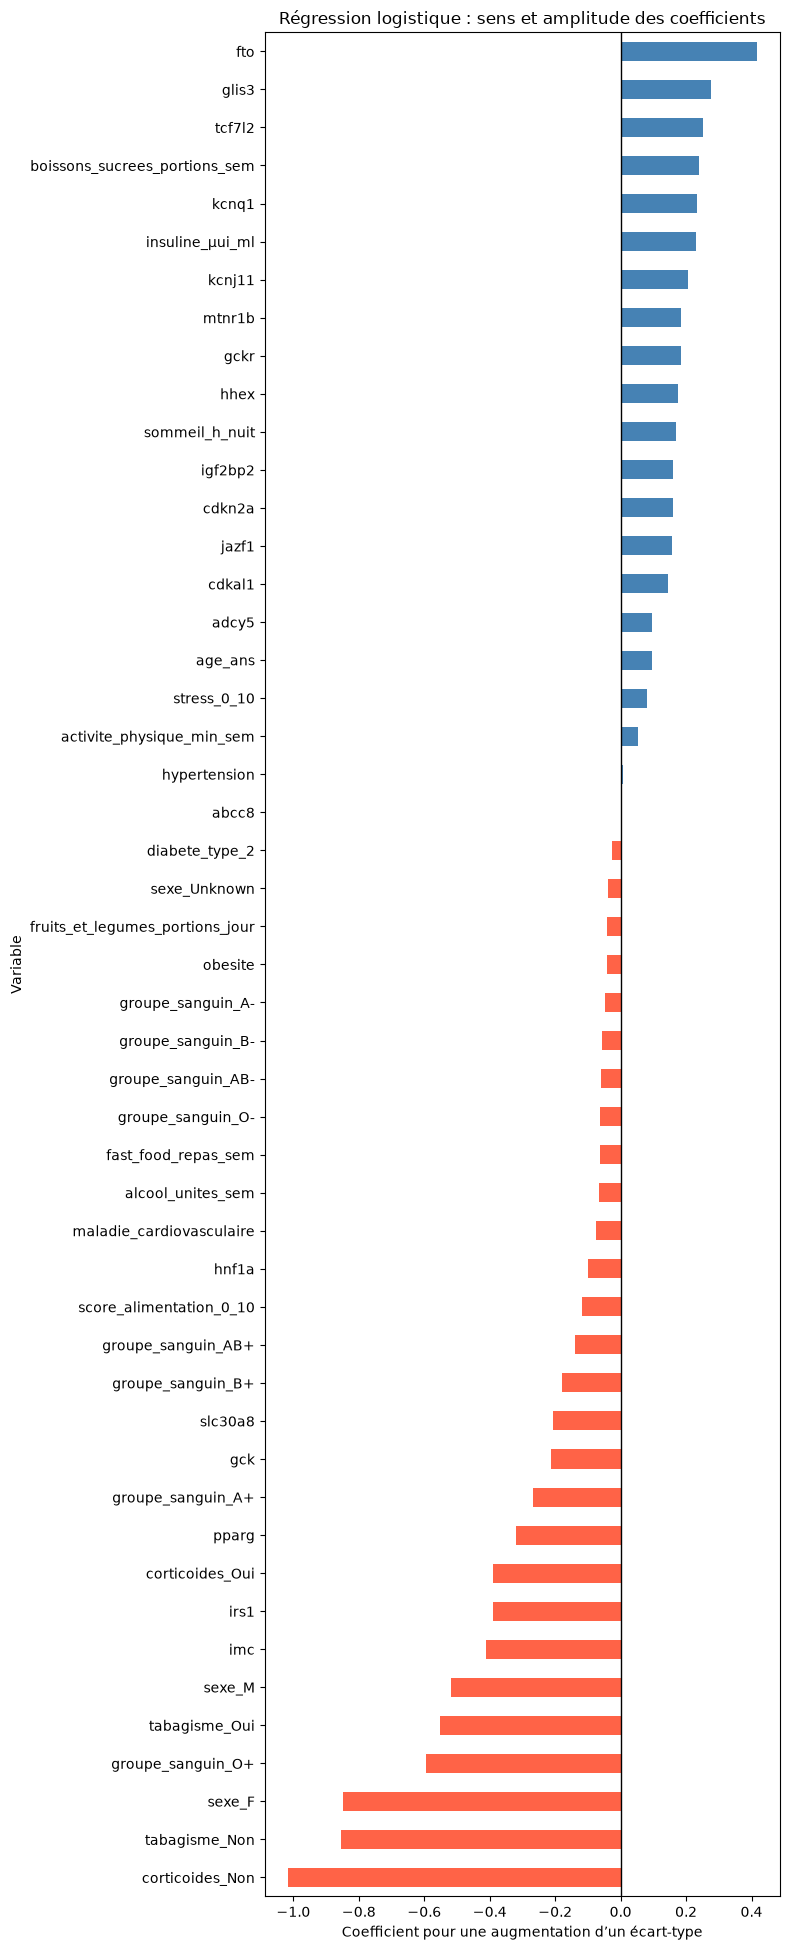

In [96]:
reg_model = reg_best.named_steps["regression"]
reg_X_train_prep = reg_best.named_steps["preprocessor"].transform(X_train)
reg_scaler = reg_best.named_steps["preprocessor"].named_steps["prep"].named_transformers_["num"]

coefficients = reg_model.coef_[0]
echelles = pd.Series(1.0, index=reg_X_train_prep.columns)
echelles[reg_scaler.feature_names_in_] = reg_scaler.scale_
coefficients_origine = coefficients / echelles.values

analyse_coefficients = pd.DataFrame({
    'coefficient_standardise': coefficients,
    'coefficient_par_unite': coefficients_origine,
    'odds_ratio_par_unite': np.exp(coefficients_origine),
}, index=reg_X_train_prep.columns)
analyse_coefficients.index.name = 'variable'
analyse_coefficients['sens'] = np.where(
    coefficients > 0, 'vers glycémie élevée',
    np.where(coefficients < 0, 'vers glycémie non élevée', 'neutre')
)
analyse_coefficients = analyse_coefficients.loc[
    analyse_coefficients['coefficient_standardise'].abs()
    .sort_values(ascending=False).index
]
display(analyse_coefficients.round(4))

# Comparer les coefficients pour une variation d'un écart-type.
coefficients_plot = analyse_coefficients['coefficient_standardise'].sort_values()
couleurs = ['steelblue' if valeur >= 0 else 'tomato'
            for valeur in coefficients_plot]
fig, ax = plt.subplots(figsize=(8, max(4, len(coefficients_plot) * 0.4)))
coefficients_plot.plot.barh(ax=ax, color=couleurs)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Coefficient pour une augmentation d’un écart-type')
ax.set_ylabel('Variable')
ax.set_title('Régression logistique : sens et amplitude des coefficients')
plt.tight_layout()
plt.show()

En conclusion pour cette regression logisitique, elle fait un très bon score, s'adapte parfaitement aux données et généralise très bien. On remarque un roc_auc score de 0.98, proche de la perfection. Cependant un recall assez faible de `0.7`. Cela veut dire que sur tous les cas positifs du test set, on en a prédit 70% correctement. Dans un contexte de prédiction médicale, il faudrait améliorer ce score. Il faut tout de fois noter que le faible taux de cas positifs dans notre dataset total influe ce nombre. Bouger un seul des hyperparamètres ou threshold peut rapidement faire basculer des positifs en négatifs et inversément.  

### XGBoost

In [97]:
# XGBoost
xgb_pipe = Pipeline([("preprocessor", preprocessor), ("xgboost", XGBClassifier(random_state=42))])
xgb_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('xgboost', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('prep', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function fea...t 0x1776cff60>
,"

In [98]:
xgb_param_grid_broad = {
 "xgboost__n_estimators": np.arange(1, 100, 10),
 "xgboost__max_depth": np.arange(1, 100, 10),
 "xgboost__learning_rate": np.linspace(0, 1, 10),
 "xgboost__subsample": np.linspace(0, 1, 10),
 "xgboost__colsample_bytree": np.linspace(0, 1, 10)
}
xgb_grid = GridSearchCV(xgb_pipe, xgb_param_grid_broad, scoring="roc_auc", cv=stra_cv)
xgb_random_grid_broad = RandomizedSearchCV(xgb_pipe, xgb_param_grid_broad, scoring="roc_auc", cv=stra_cv, n_iter=50, random_state=42)

In [99]:
xgb_random_grid_broad.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'xgboost__colsample_bytree': array([0. ..., 1. ]), 'xgboost__learning_rate': array([0. ..., 1. ]), 'xgboost__max_depth': array([ 1, 11..., 71, 81, 91]), 'xgboost__n_estimators': array([ 1, 11..., 71, 81, 91]), ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at t

In [100]:
xgb_random_grid_broad.best_params_

{'xgboost__subsample': np.float64(0.4444444444444444),
 'xgboost__n_estimators': np.int64(91),
 'xgboost__max_depth': np.int64(11),
 'xgboost__learning_rate': np.float64(0.7777777777777777),
 'xgboost__colsample_bytree': np.float64(0.3333333333333333)}

In [101]:
xgb_param_grid = {
 "xgboost__n_estimators": np.arange(50, 100),
 "xgboost__max_depth": np.arange(0, 50),
 "xgboost__learning_rate": np.linspace(0.2, 0.8, 100),
 "xgboost__subsample": np.linspace(0.2, 0.7, 100),
 "xgboost__colsample_bytree": np.linspace(0.1, 0.7, 100)
}
xgb_random_grid = RandomizedSearchCV(xgb_pipe, xgb_param_grid, scoring="roc_auc", cv=stra_cv, n_iter=100, random_state=42, return_train_score=True)

In [102]:
xgb_random_grid.fit(X_train, y_train)
xgb_best = xgb_random_grid.best_estimator_
xgb_random_grid.best_params_

{'xgboost__subsample': np.float64(0.6393939393939394),
 'xgboost__n_estimators': np.int64(72),
 'xgboost__max_depth': np.int64(36),
 'xgboost__learning_rate': np.float64(0.3393939393939394),
 'xgboost__colsample_bytree': np.float64(0.28787878787878785)}

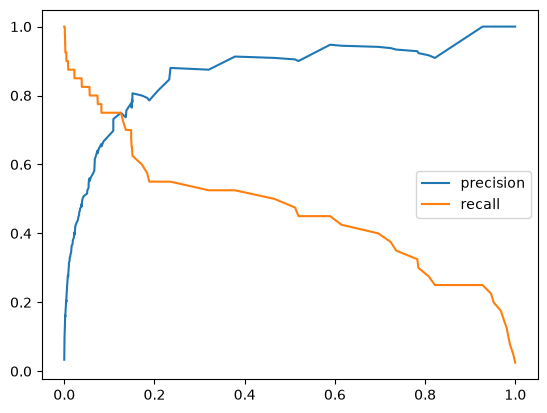

In [103]:
xgb_cv_proba = cross_val_predict(xgb_best, X_train, y_train, cv=stra_cv, method="predict_proba")[:, 1]
xgb_precision, xgb_recall, xgb_threshold = precision_recall_curve(y_train, xgb_cv_proba)

plt.plot(xgb_threshold, xgb_precision[:-1])
plt.plot(xgb_threshold, xgb_recall[:-1])
plt.legend(["precision", "recall"])
plt.show()

In [104]:
xgb_best

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('xgboost', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['age_ans','sexe','poids_kg',...,'glis3','jazf1','hnf1a']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('prep', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected direct

In [105]:
bilan_cv = []
for nom, recherche in [('Régression logistique', reg_grid), ('XGBoost', xgb_random_grid)]:
    i = recherche.best_index_
    scores_cv = recherche.cv_results_
    bilan_cv.append({
        'modele': nom,
        'auc_train_moyenne': scores_cv['mean_train_score'][i],
        'auc_cv_moyenne': scores_cv['mean_test_score'][i],
        'auc_cv_ecart_type': scores_cv['std_test_score'][i],
        'ecart_train_cv': scores_cv['mean_train_score'][i] - scores_cv['mean_test_score'][i]
    })
display(pd.DataFrame(bilan_cv).set_index('modele').round(4))

,auc_train_moyenne,auc_cv_moyenne,auc_cv_ecart_type,ecart_train_cv
modele,,,,
Régression logistique,0.9949,0.9837,0.0146,0.0112
XGBoost,1.0000,0.9761,0.0204,0.0239


## 10. Évaluation et comparaison des modèles sur le test

In [106]:
xgb_y_pred = xgb_best.predict(X_test)
xgb_y_proba = xgb_best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, xgb_y_pred))
print(f"AUC ROC de XGBoost : {roc_auc_score(y_test, xgb_y_proba):.4f}")

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       290
           1       1.00      0.50      0.67        10

    accuracy                           0.98       300
   macro avg       0.99      0.75      0.83       300
weighted avg       0.98      0.98      0.98       300

AUC ROC de XGBoost : 0.9869


In [107]:
resultats = pd.DataFrame({
    'Modèle': ['Régression logistique', 'XGBoost'],
    'Accuracy': [accuracy_score(y_test, reg_y_pred), accuracy_score(y_test, xgb_y_pred)],
    'Précision': [precision_score(y_test, reg_y_pred), precision_score(y_test, xgb_y_pred)],
    'Recall': [recall_score(y_test, reg_y_pred), recall_score(y_test, xgb_y_pred)],
    'F1-score': [f1_score(y_test, reg_y_pred), f1_score(y_test, xgb_y_pred)],
    'AUC ROC': [roc_auc_score(y_test, reg_y_proba), roc_auc_score(y_test, xgb_y_proba)]
})

resultats = resultats.sort_values('AUC ROC', ascending=False, kind='stable')
resultats

,Modèle,Accuracy,Précision,Recall,F1-score,AUC ROC
1,XGBoost,0.983333,1.000000,0.5,0.666667,0.986897
0,Régression logistique,0.983333,0.857143,0.6,0.705882,0.971379


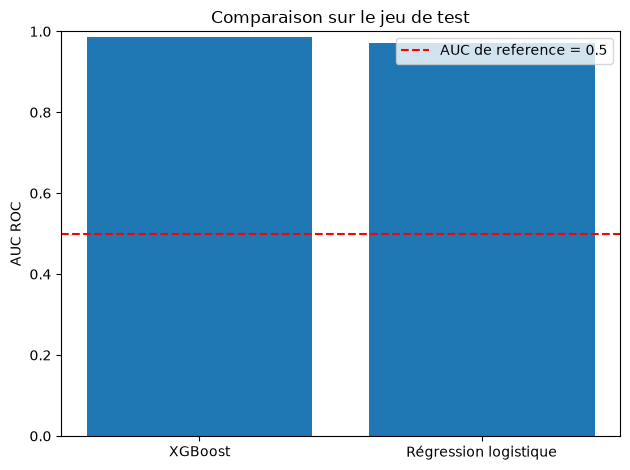

In [108]:
# Une probabilité constante ne permet pas de classer les patients.
probabilites_reference = [y_train.mean()] * len(y_test)
score_reference = roc_auc_score(y_test, probabilites_reference)

plt.bar(resultats['Modèle'], resultats['AUC ROC'])
plt.axhline(score_reference, color='red', linestyle='--', label='AUC de reference = 0.5')
plt.ylabel('AUC ROC')
plt.ylim(0, 1)
plt.title('Comparaison sur le jeu de test')
plt.legend()
plt.tight_layout()
plt.show()

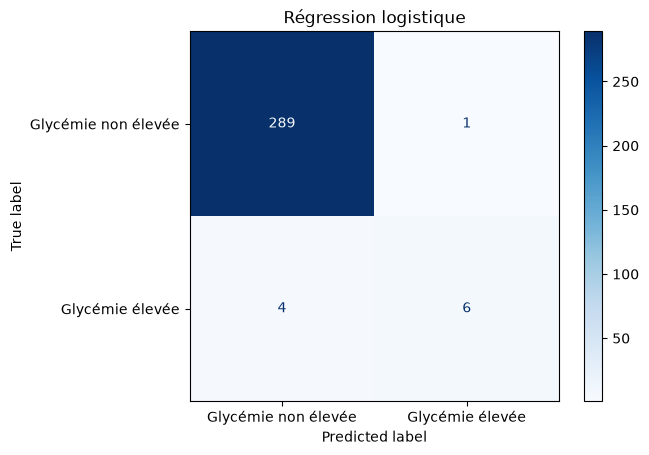

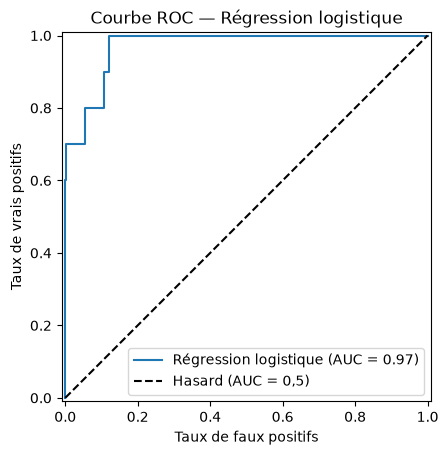

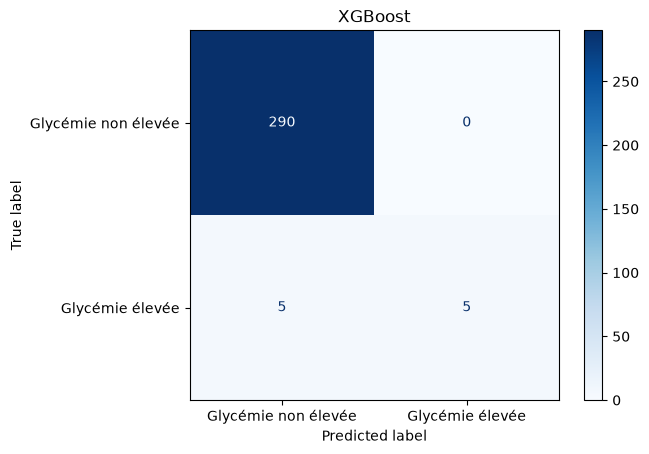

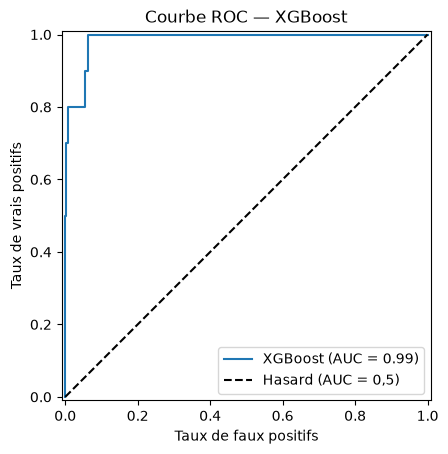

In [109]:
for nom, predictions, probabilites in [
    ('Régression logistique', reg_y_pred, reg_y_proba),
    ('XGBoost', xgb_y_pred, xgb_y_proba),
]:
    # Matrice de confusion
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=['Glycémie non élevée', 'Glycémie élevée'],
        cmap='Blues'
    )
    plt.title(nom)
    plt.show()

    # Courbe ROC
    RocCurveDisplay.from_predictions(
        y_test,
        probabilites,
        name=nom
    )
    plt.plot([0, 1], [0, 1], 'k--', label='Hasard (AUC = 0,5)')
    plt.xlabel('Taux de faux positifs')
    plt.ylabel('Taux de vrais positifs')
    plt.title(f'Courbe ROC — {nom}')
    plt.legend()
    plt.show()

## 10. Interprétation de XGBoost avec les valeurs SHAP

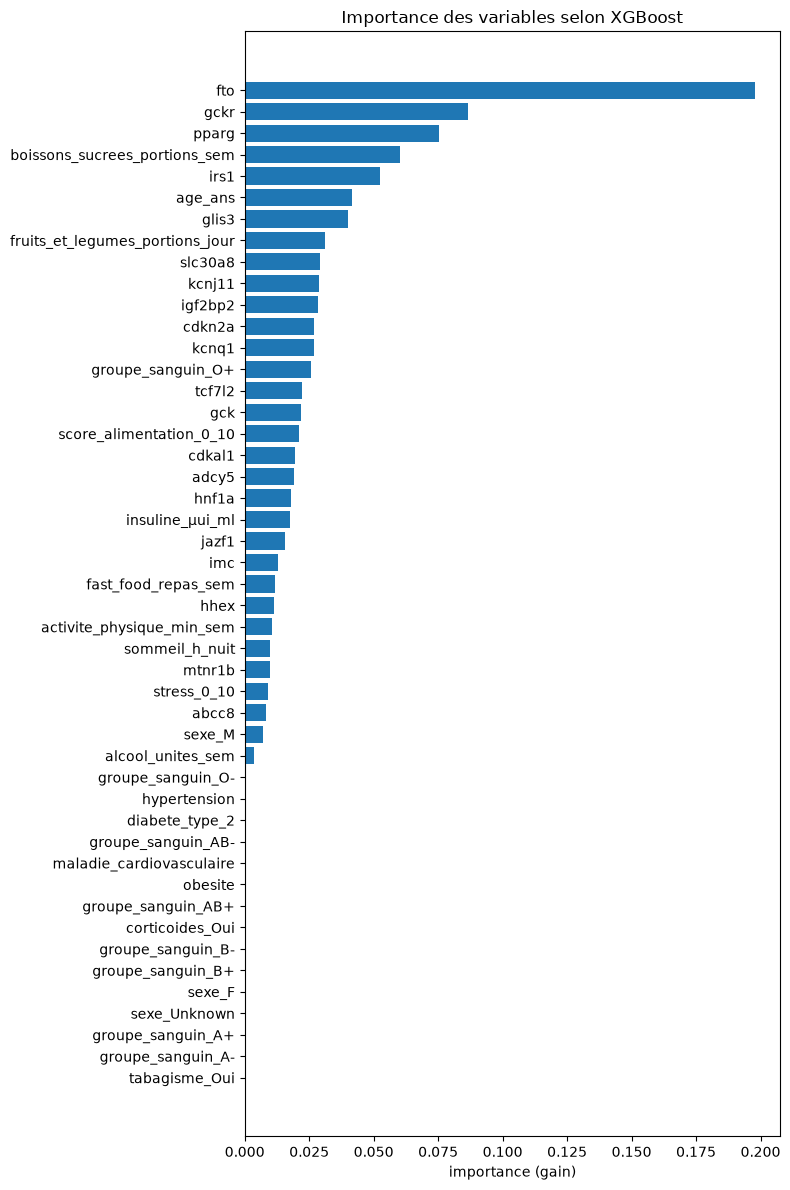

Variables jamais utilisées : ['tabagisme_Oui', 'groupe_sanguin_A-', 'groupe_sanguin_A+', 'sexe_Unknown', 'sexe_F', 'groupe_sanguin_B+', 'groupe_sanguin_B-', 'corticoides_Oui', 'groupe_sanguin_AB+', 'obesite', 'maladie_cardiovasculaire', 'groupe_sanguin_AB-', 'diabete_type_2', 'hypertension', 'groupe_sanguin_O-']


In [110]:
xgb_model = xgb_best.named_steps["xgboost"]

xgb_importances = Series(data=xgb_model.feature_importances_, index=xgb_model.feature_names_in_).sort_values()

plt.figure(figsize=(8, 12))
plt.barh(xgb_importances.index, xgb_importances.values)
plt.xlabel("importance (gain)")
plt.title("Importance des variables selon XGBoost")
plt.tight_layout()
plt.show()

print("Variables jamais utilisées :", xgb_importances[xgb_importances == 0].index.tolist())

In [111]:
import shap

# --- Préparation ---
xgb_preprocessor_fit = xgb_best.named_steps["preprocessor"]
xgb_model = xgb_best.named_steps["xgboost"]

# SHAP explique le modèle XGBoost, donc il lui faut les données déjà transformées
xgb_X_test_prep = xgb_preprocessor_fit.transform(X_test)

xgb_explainer = shap.TreeExplainer(xgb_model)
xgb_shap_values = xgb_explainer(xgb_X_test_prep)

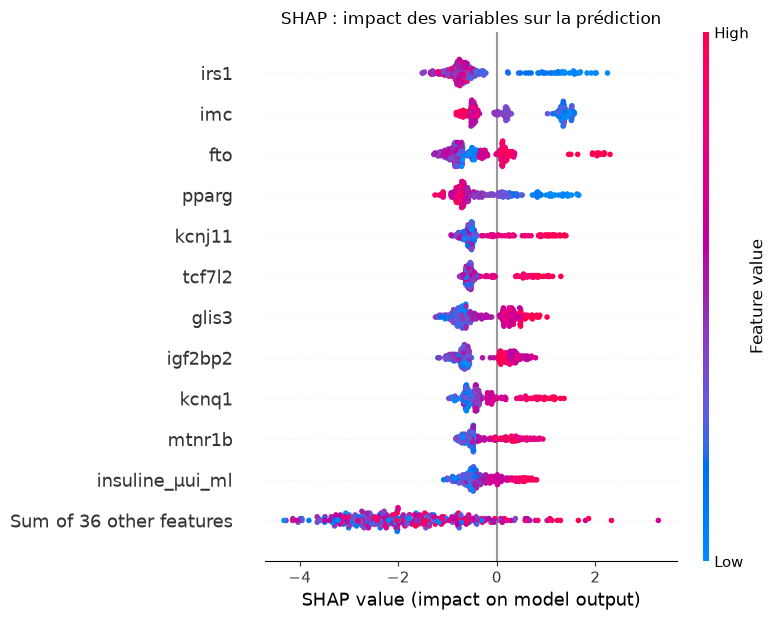

In [112]:
# --- 1. Beeswarm : vue globale ---
shap.plots.beeswarm(xgb_shap_values, max_display=12, show=False)
plt.title("SHAP : impact des variables sur la prédiction")
plt.tight_layout()
plt.show()

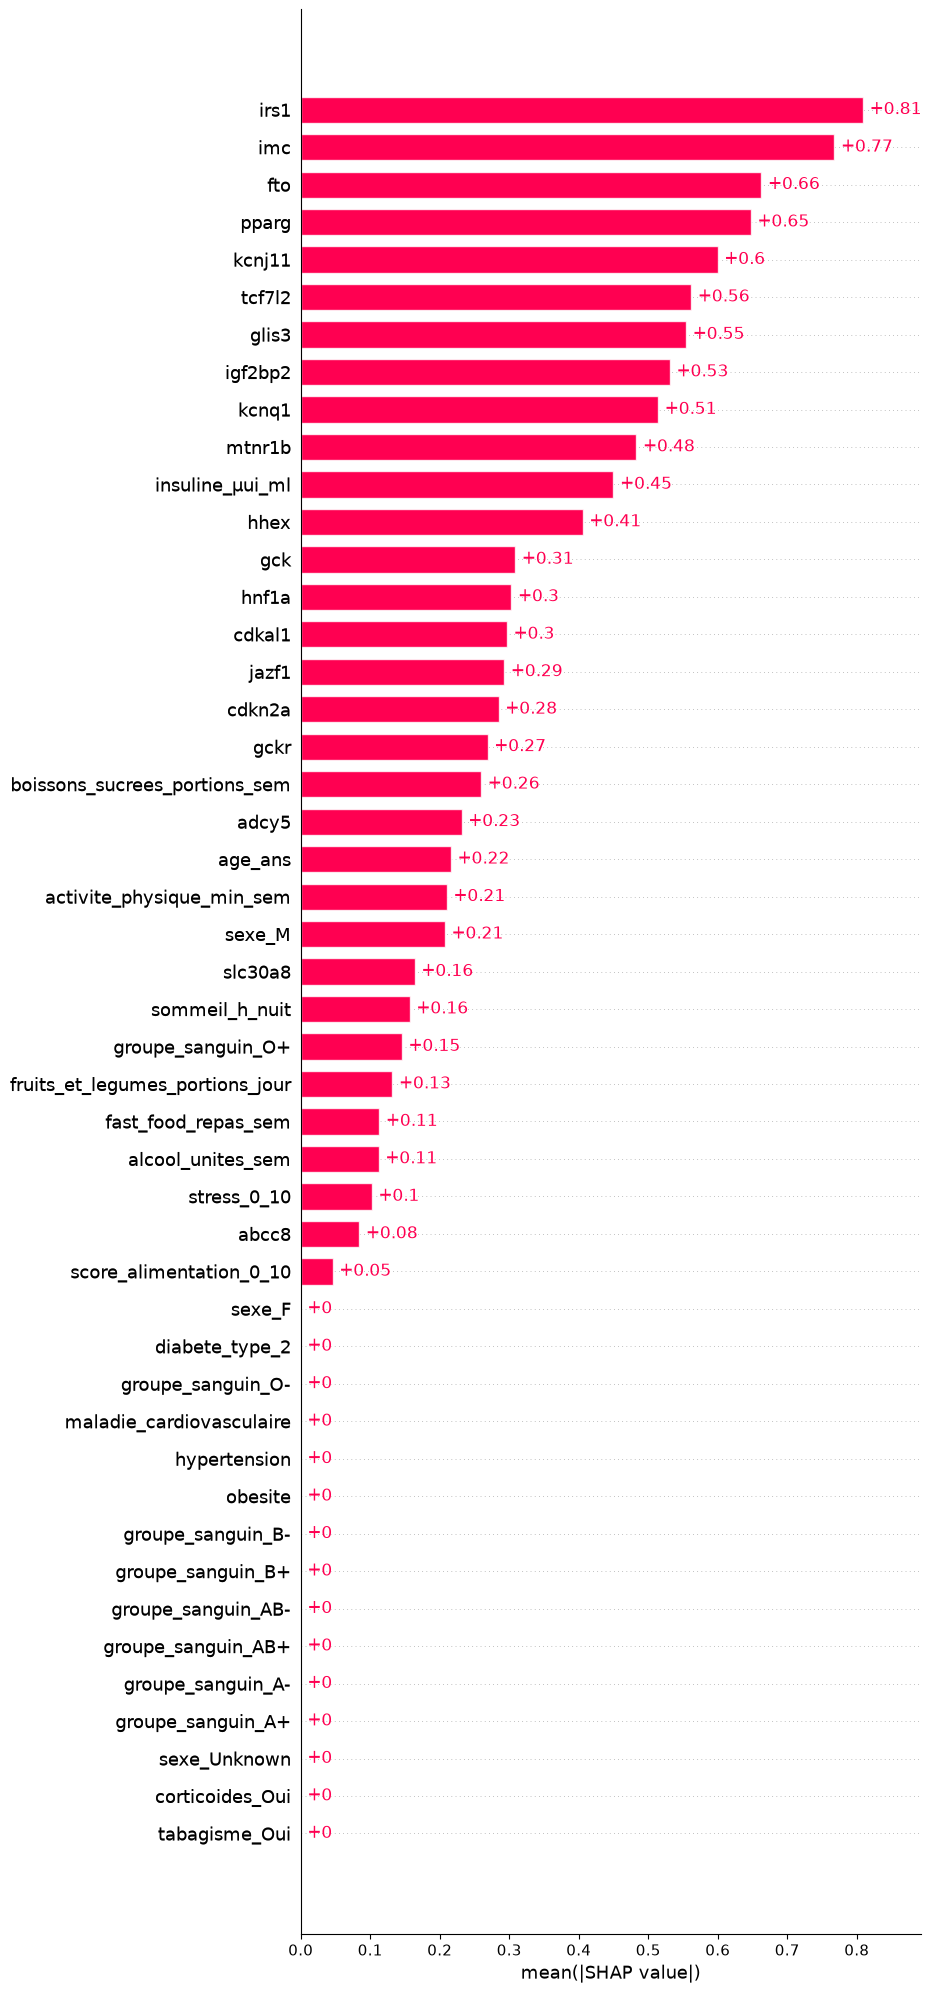

In [113]:
# Importance globale : moyenne de la valeur absolue des contributions.
shap.plots.bar(xgb_shap_values, max_display=len(xgb_X_test_prep.columns))

In [114]:
contributions_shap = pd.DataFrame(
    xgb_shap_values.values, index=xgb_X_test_prep.index, columns=xgb_X_test_prep.columns
)
importance_shap = pd.DataFrame({
    'impact_moyen_absolu': contributions_shap.abs().mean(),
    'contribution_moyenne': contributions_shap.mean(),
    'proportion_contributions_positives': (contributions_shap > 0).mean()
}).sort_values('impact_moyen_absolu', ascending=False)
total_impact = importance_shap['impact_moyen_absolu'].sum()
importance_shap['part_impact_absolu'] = (
    importance_shap['impact_moyen_absolu'] / total_impact if total_impact > 0 else 0.0
)
display(importance_shap.round(4))

principales_variables = importance_shap.head(3).index.tolist()
print('Variables les plus influentes :', ', '.join(principales_variables))
for variable in principales_variables:
    ligne = importance_shap.loc[variable]
    print(f"{variable} : impact absolu moyen = {ligne['impact_moyen_absolu']:.3f} log-odds, "
          f"part relative = {ligne['part_impact_absolu']:.1%}.")

,impact_moyen_absolu,contribution_moyenne,proportion_contributions_positives,part_impact_absolu
irs1,0.8090,-0.4712,0.1367,0.0741
imc,0.7677,0.2834,0.5267,0.0703
fto,0.6627,-0.3868,0.2800,0.0607
pparg,0.6475,-0.3232,0.2867,0.0593
kcnj11,0.5997,-0.3593,0.1500,0.0549
tcf7l2,0.5617,-0.3419,0.1467,0.0514
glis3,0.5544,-0.2620,0.4267,0.0508
igf2bp2,0.5311,-0.2778,0.4400,0.0486
kcnq1,0.5141,-0.2822,0.1533,0.0471
mtnr1b,0.4829,-0.2534,0.2800,0.0442


Variables les plus influentes : irs1, imc, fto
irs1 : impact absolu moyen = 0.809 log-odds, part relative = 7.4%.
imc : impact absolu moyen = 0.768 log-odds, part relative = 7.0%.
fto : impact absolu moyen = 0.663 log-odds, part relative = 6.1%.


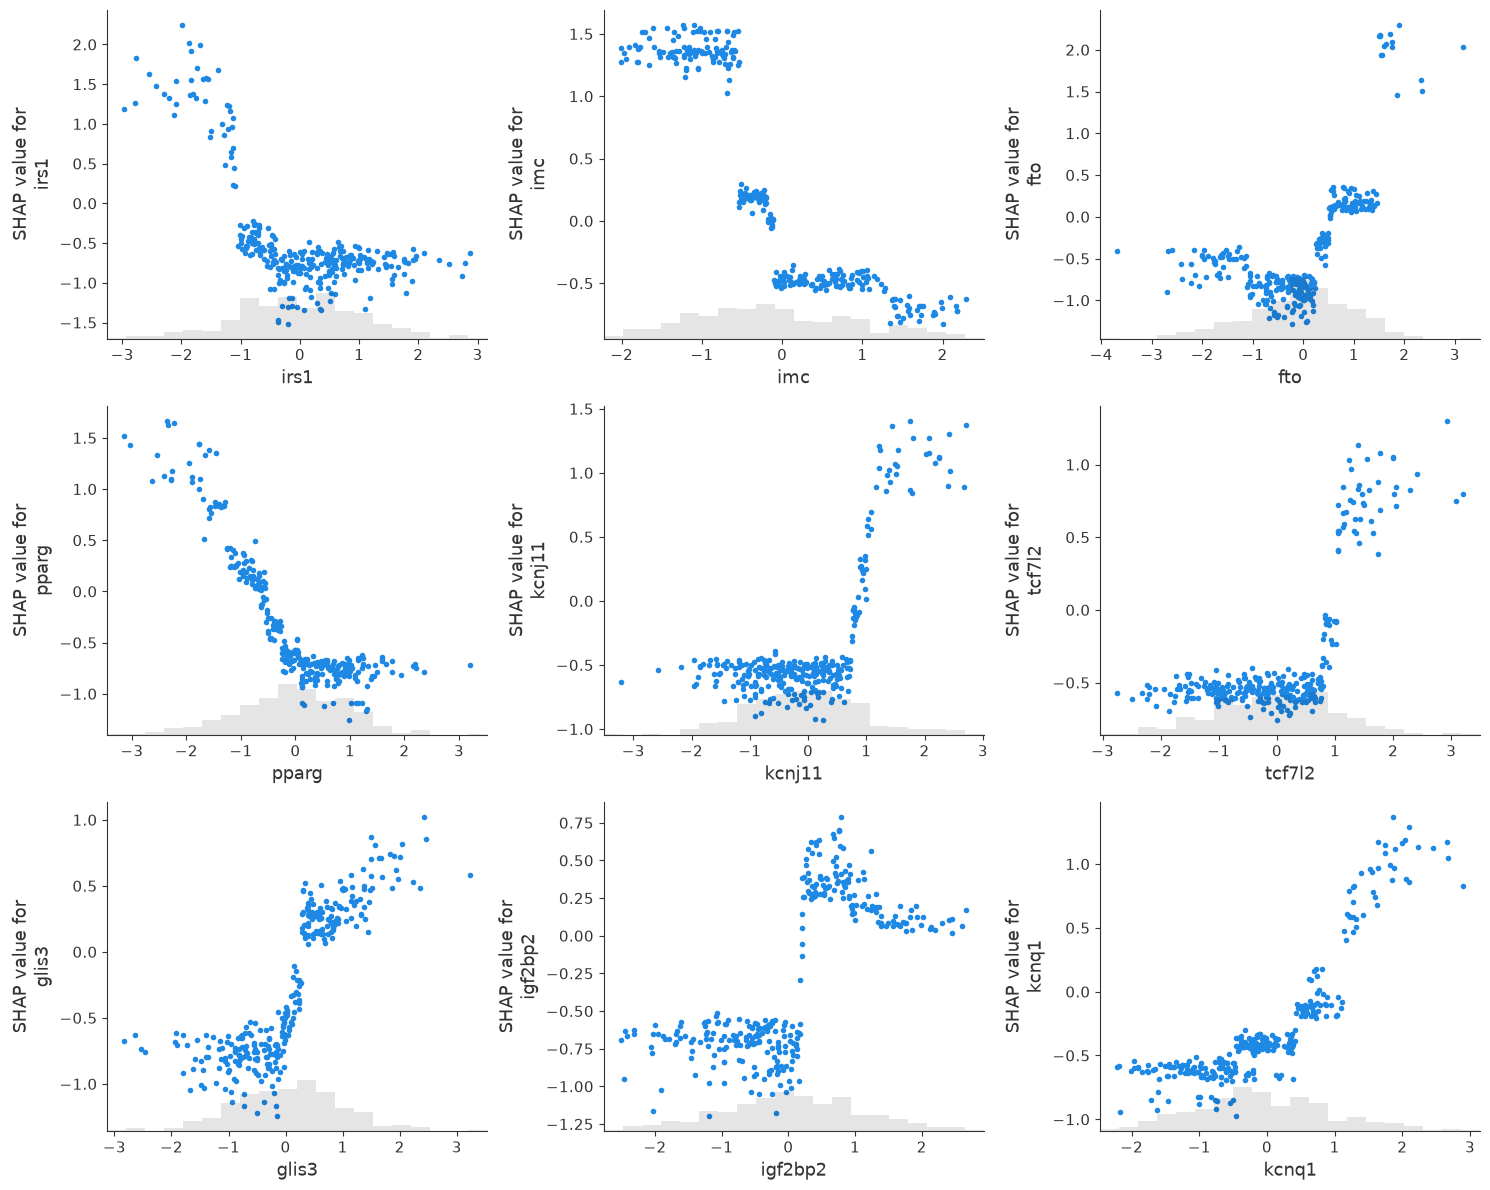

In [115]:
# --- 3. Scatter plots : valeur de la variable -> contribution ---
xgb_shap_importance = Series(np.abs(xgb_shap_values.values).mean(axis=0), index=xgb_X_test_prep.columns).sort_values(ascending=False)
xgb_shap_top = xgb_shap_importance.index[:9]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flat, xgb_shap_top):
    shap.plots.scatter(xgb_shap_values[:, col], ax=ax, show=False)
plt.tight_layout()
plt.show()

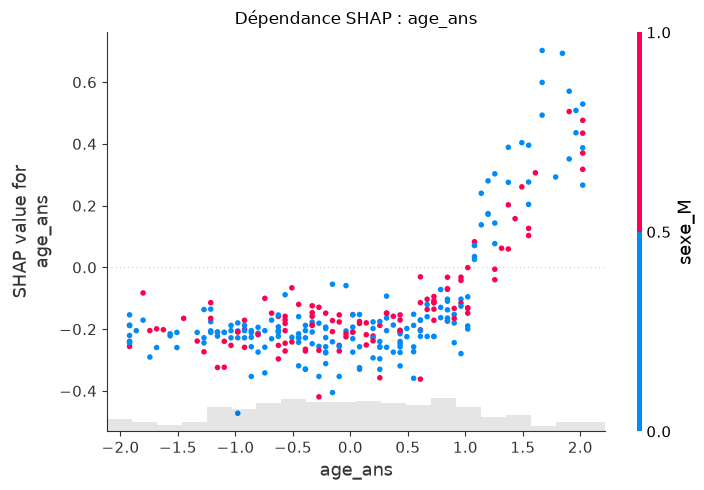

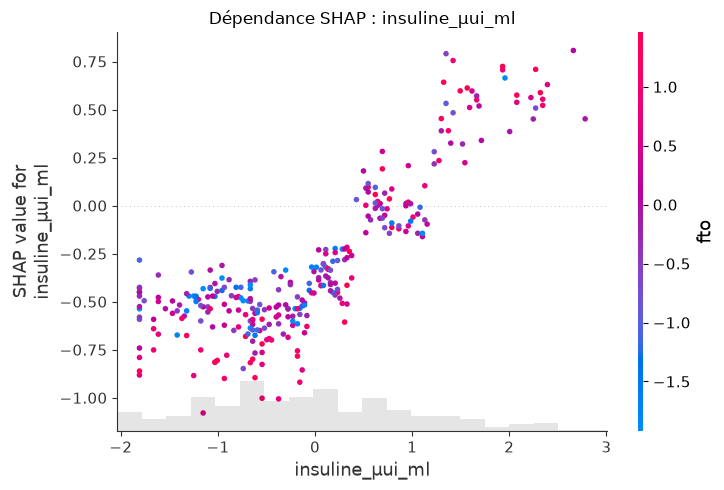

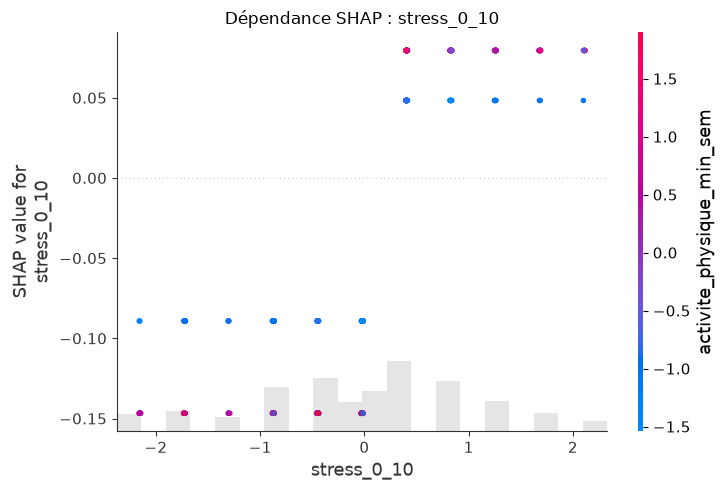

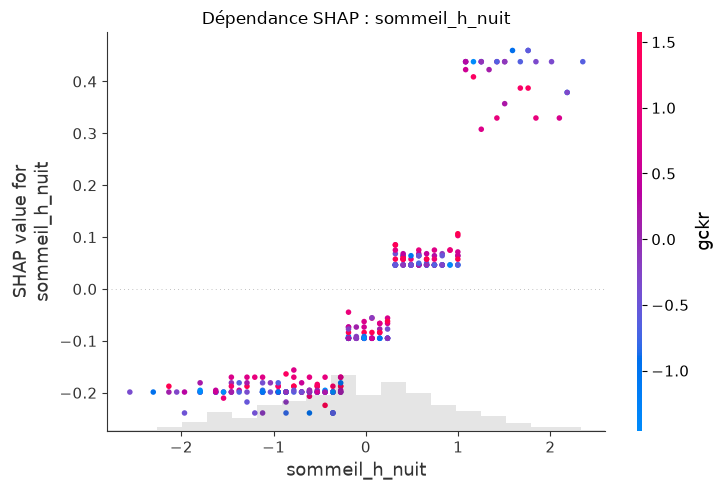

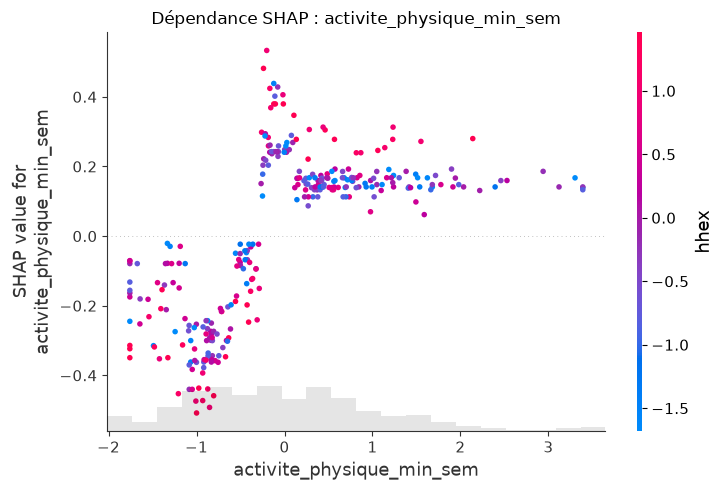

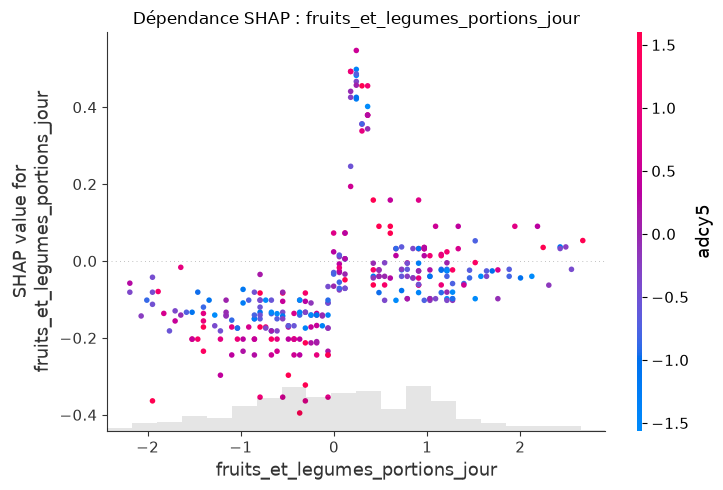

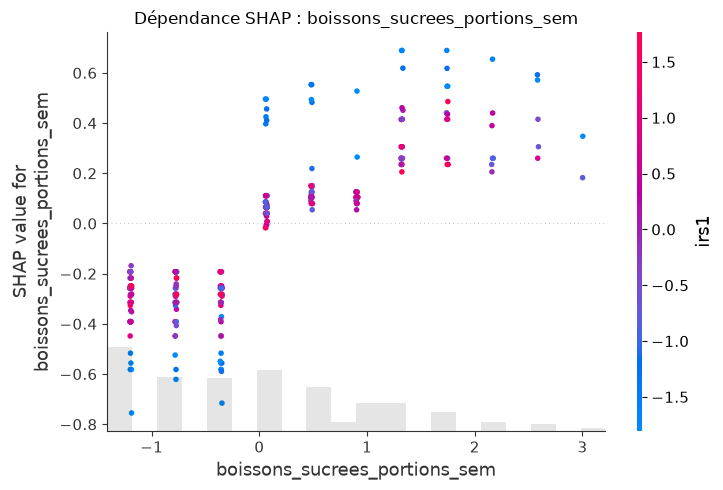

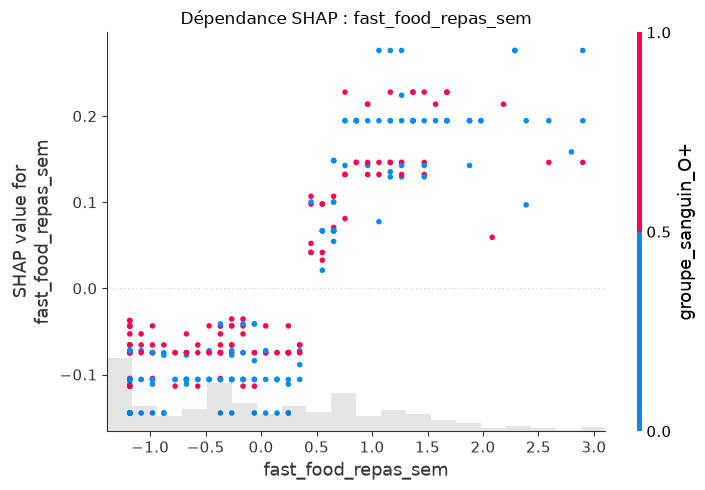

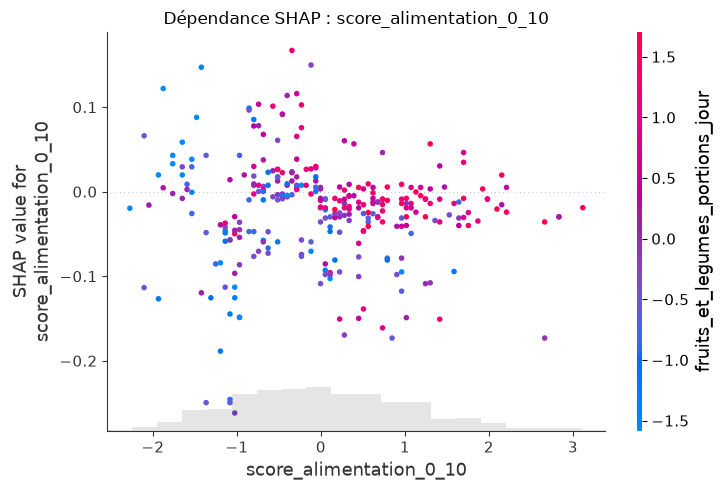

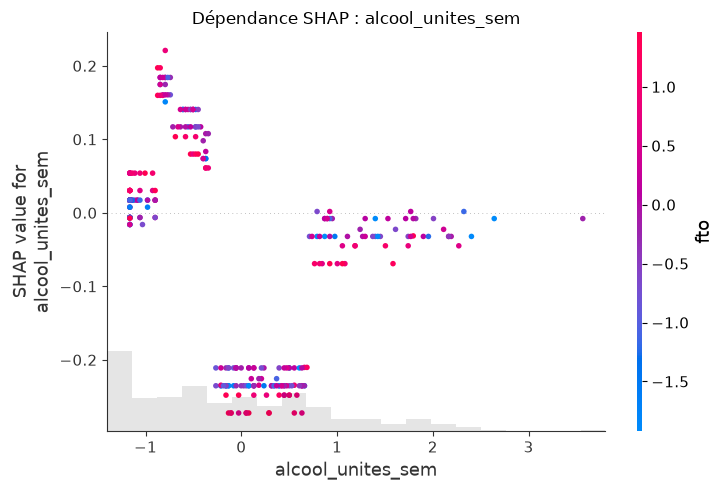

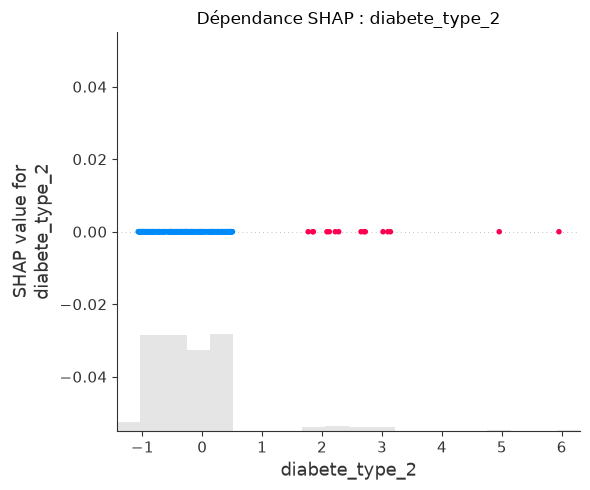

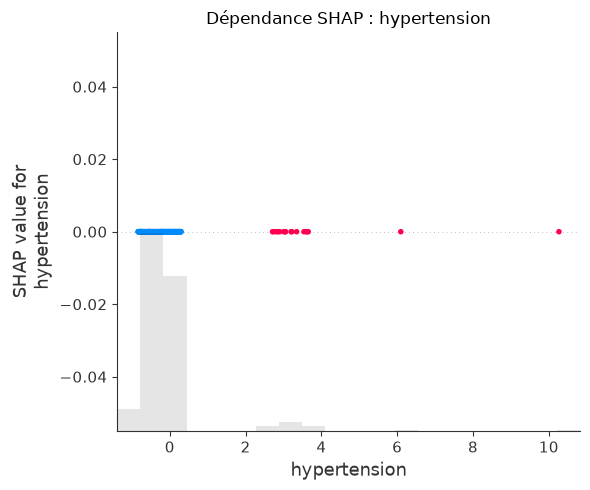

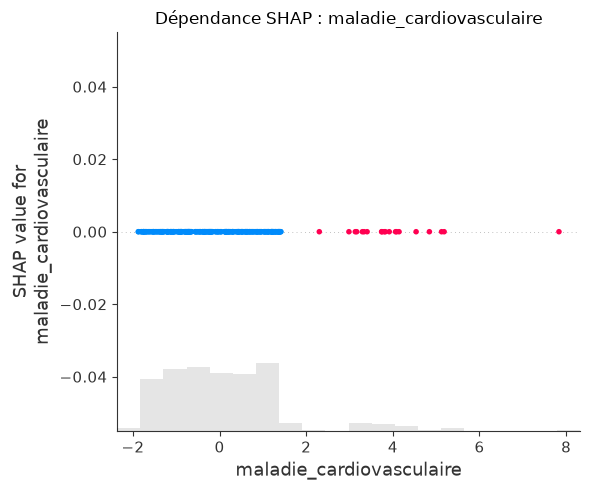

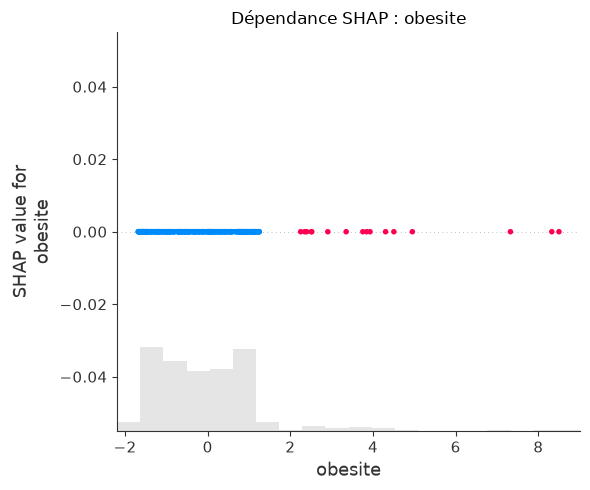

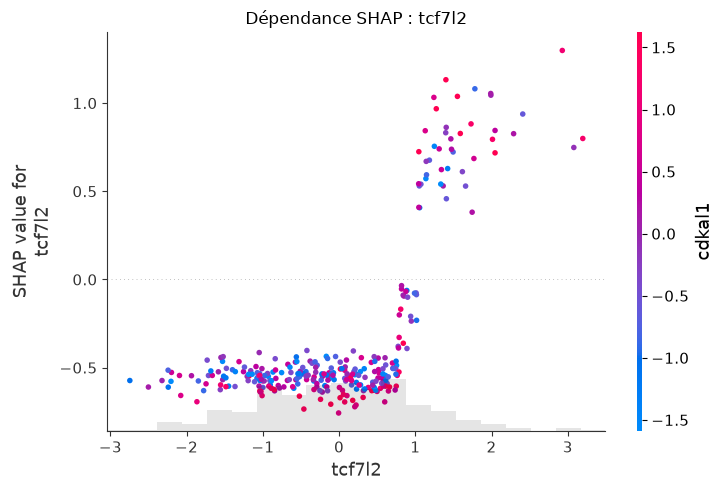

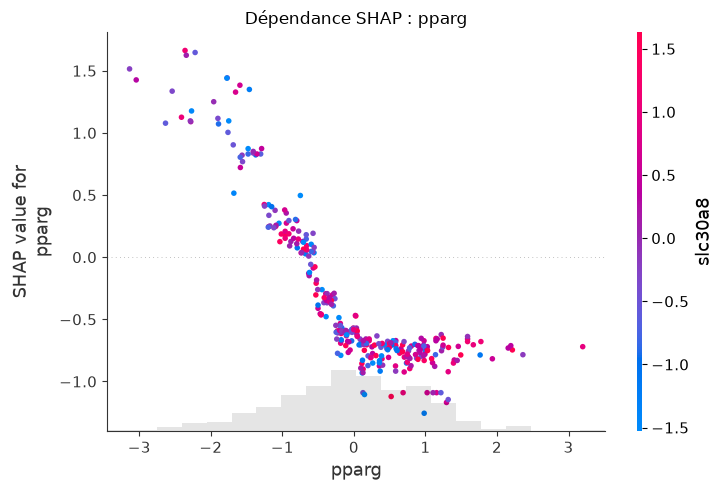

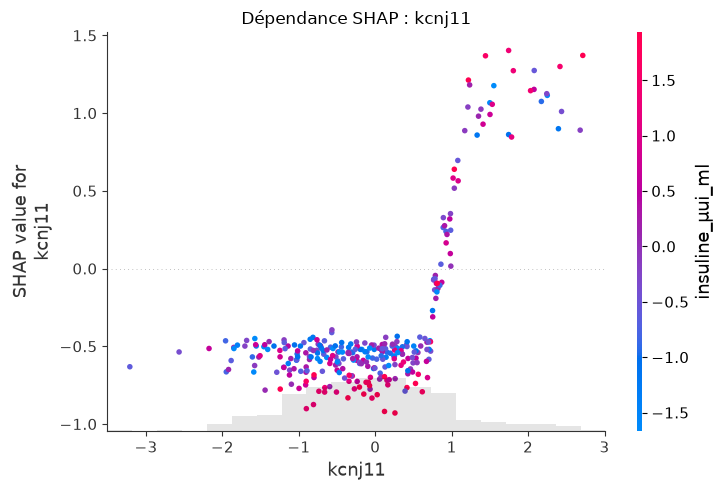

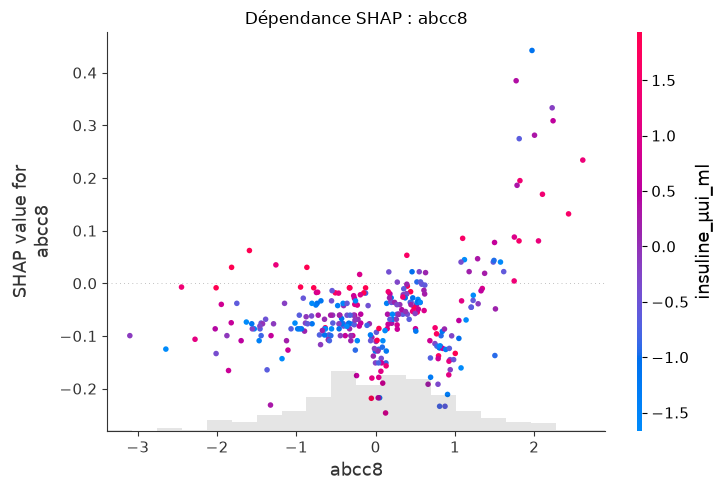

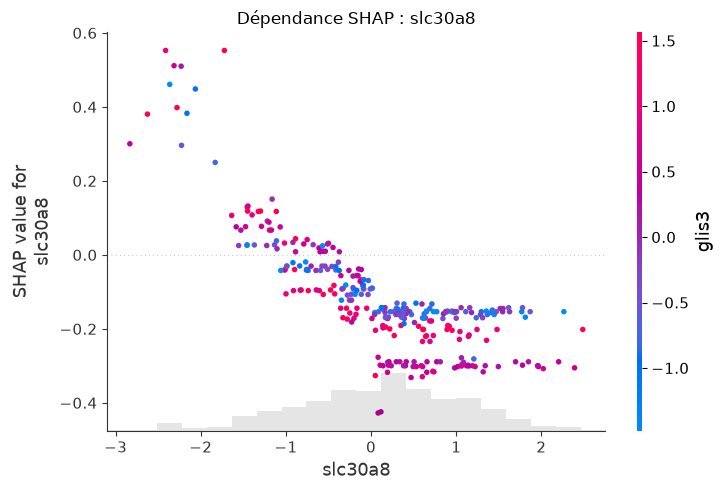

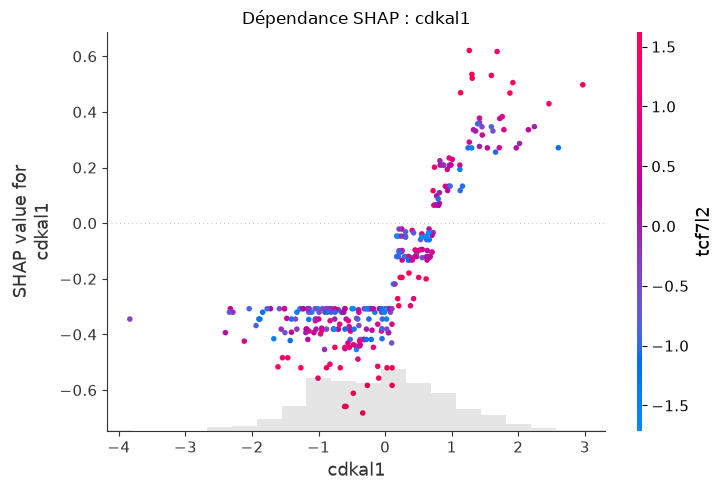

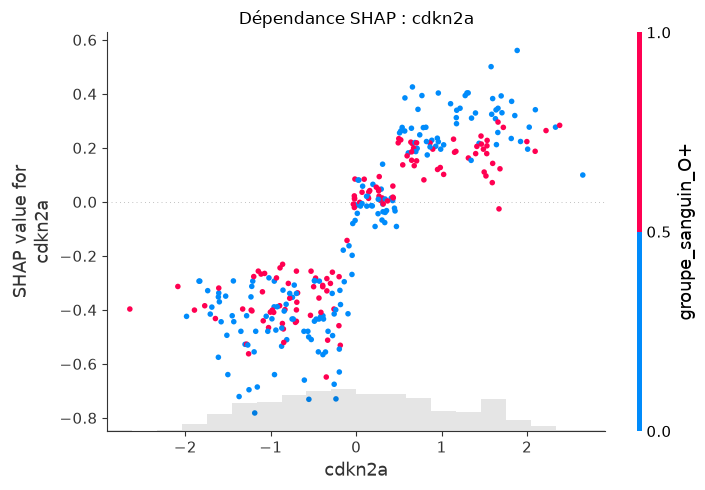

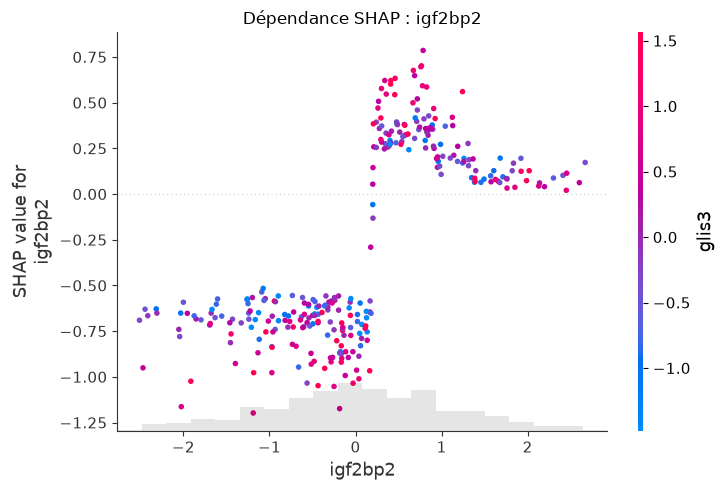

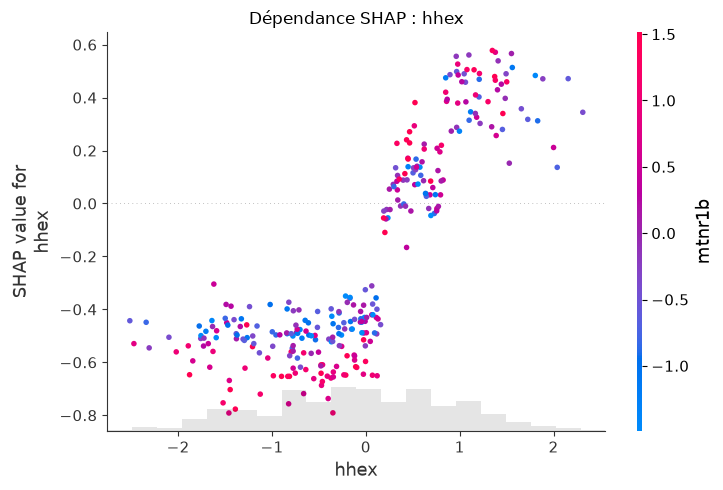

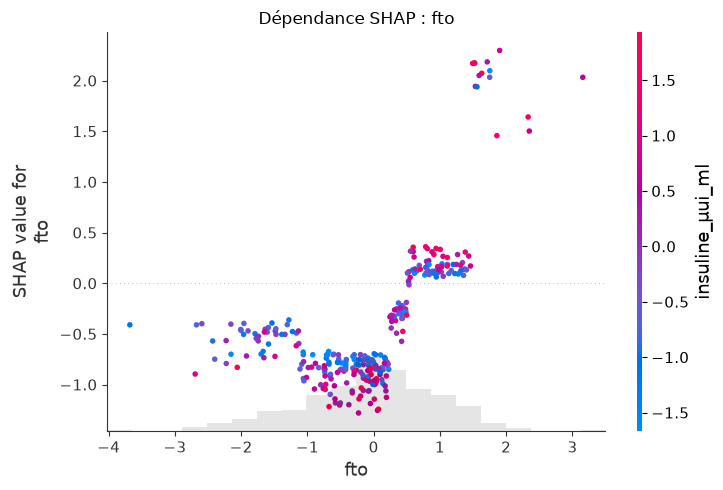

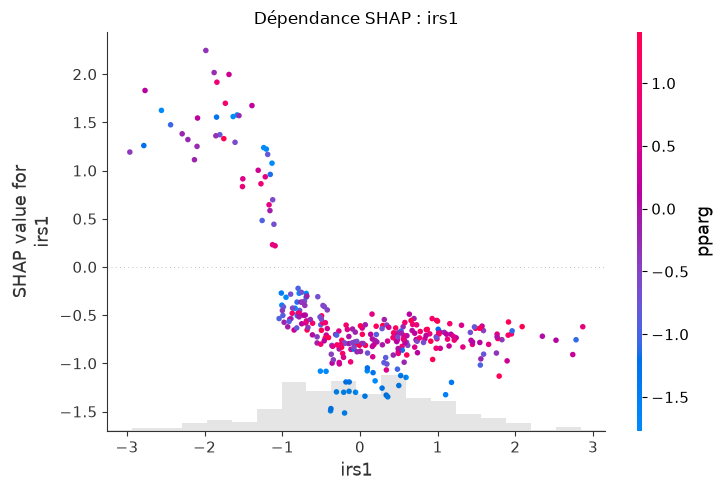

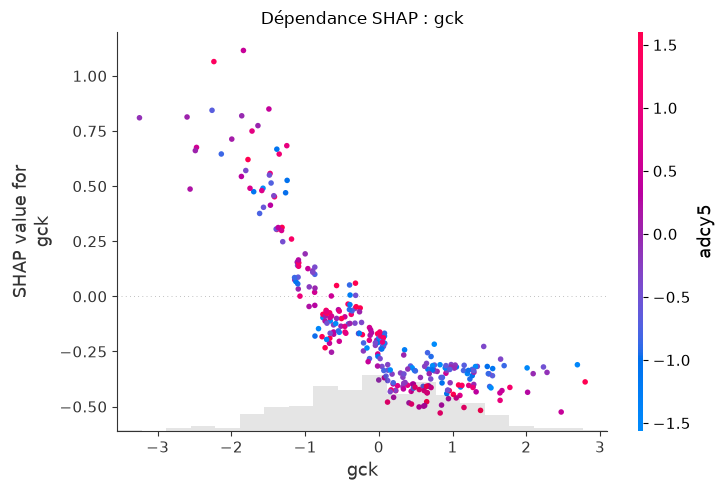

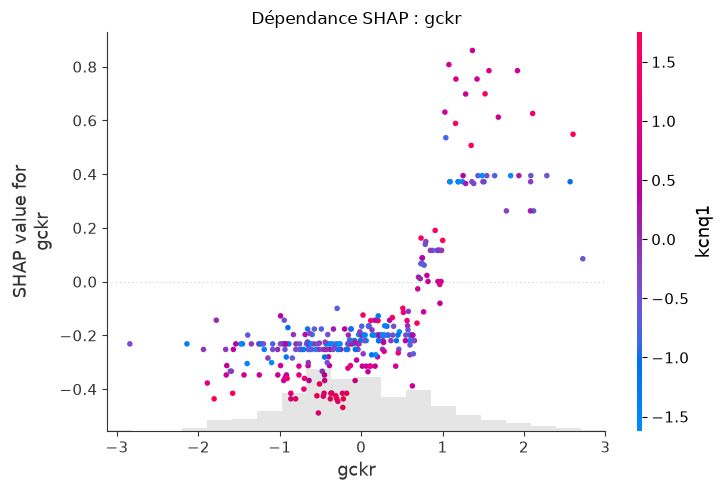

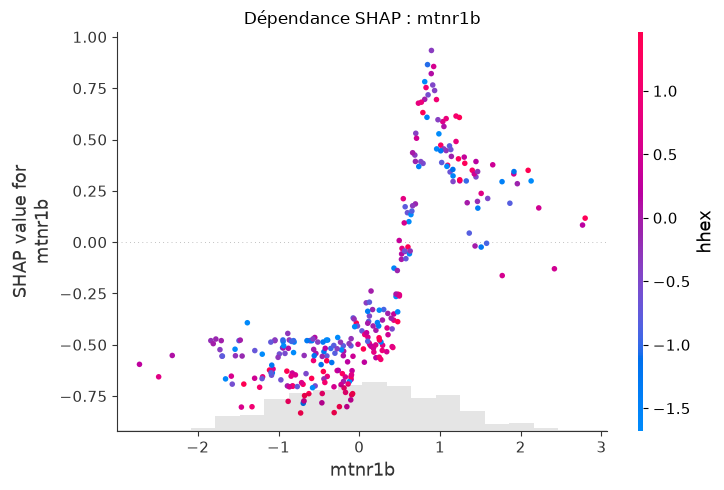

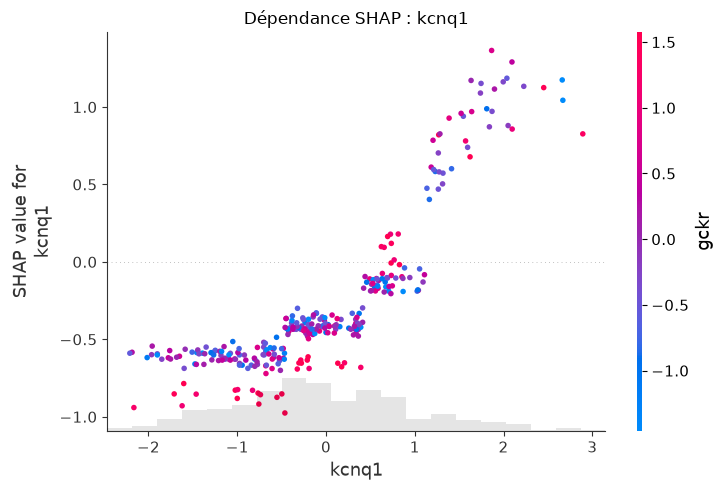

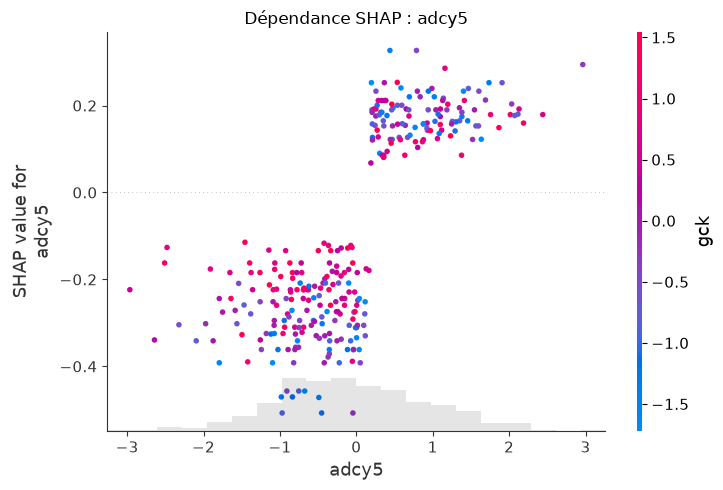

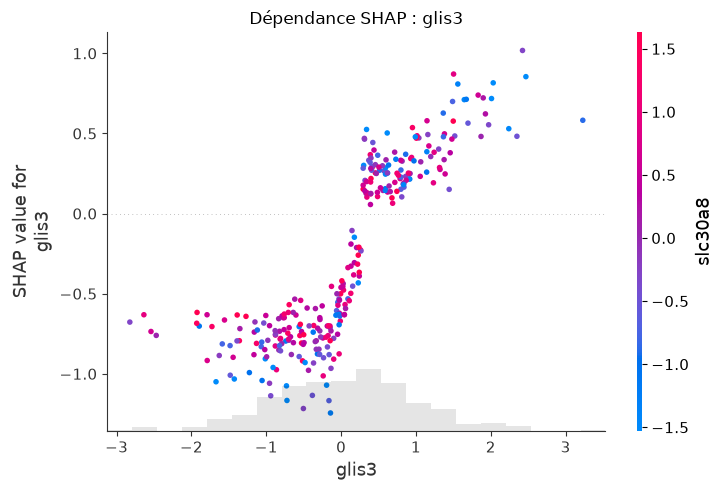

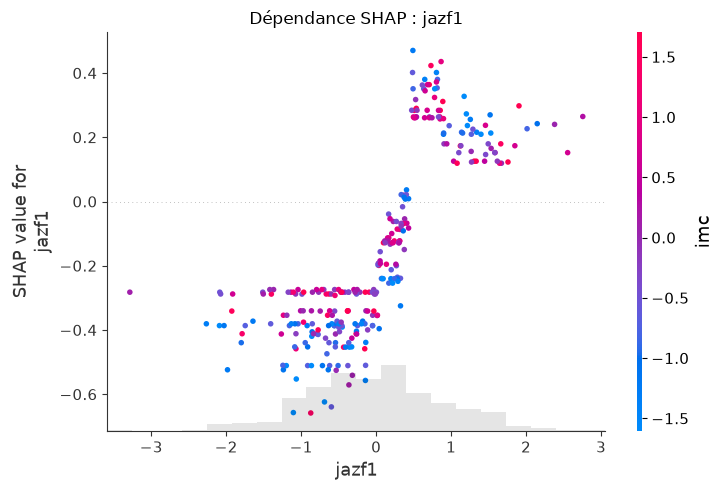

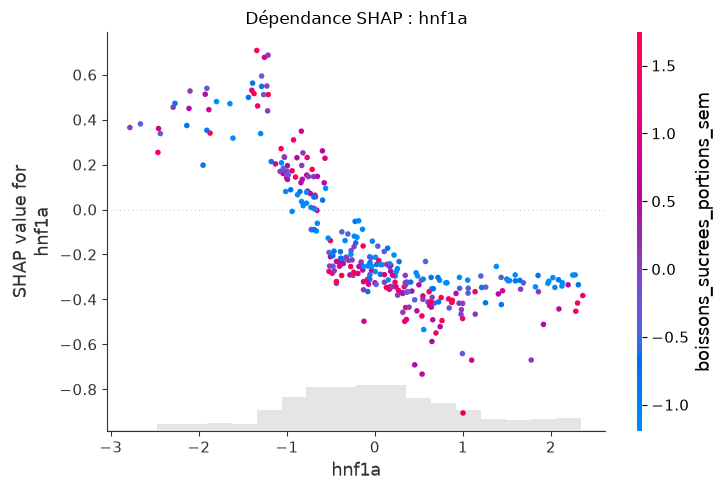

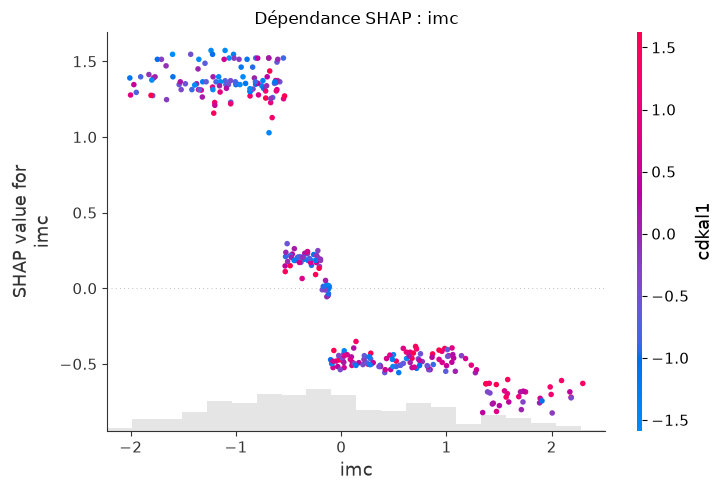

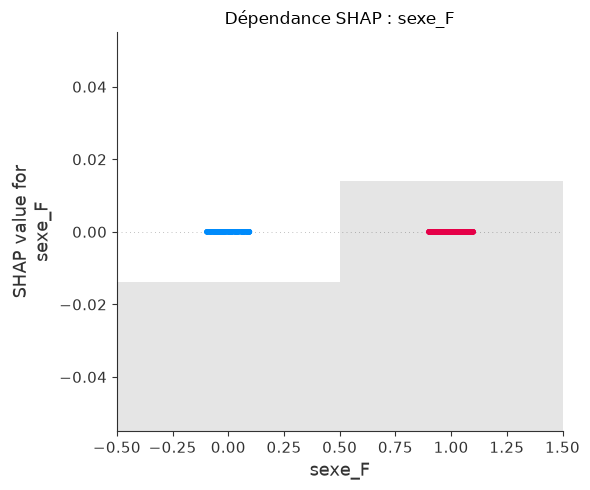

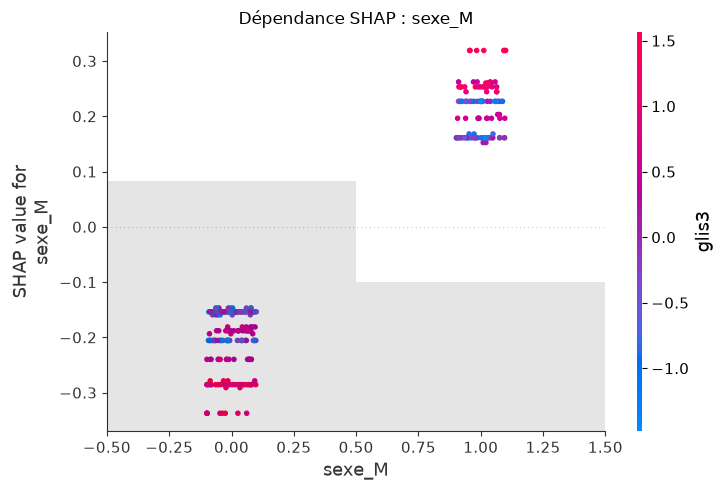

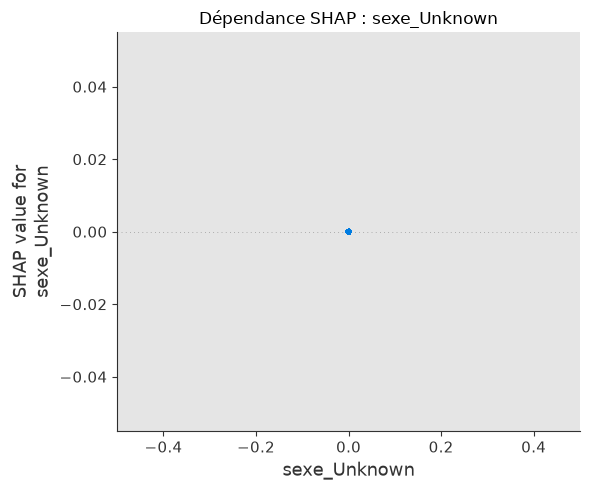

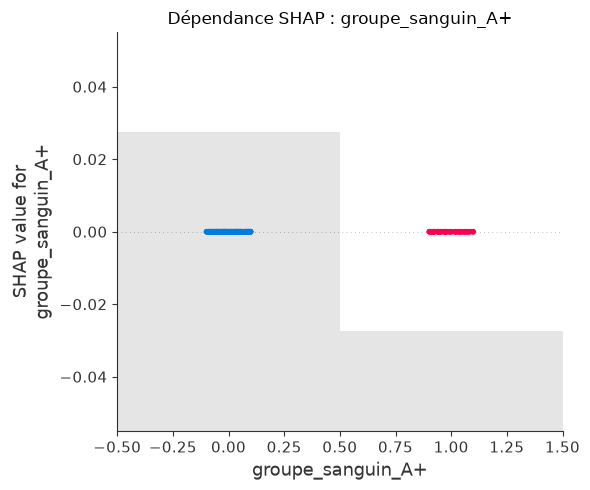

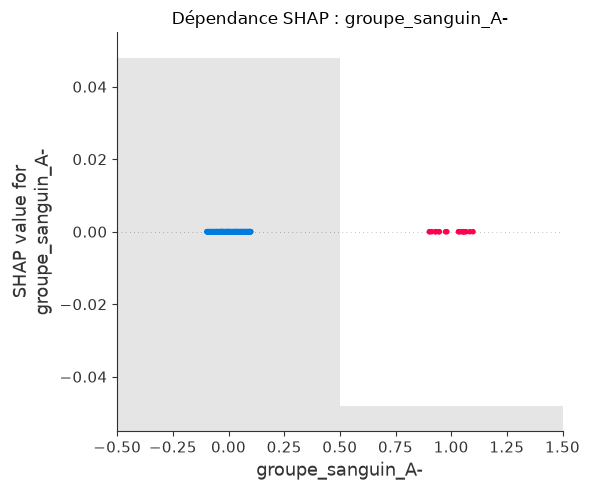

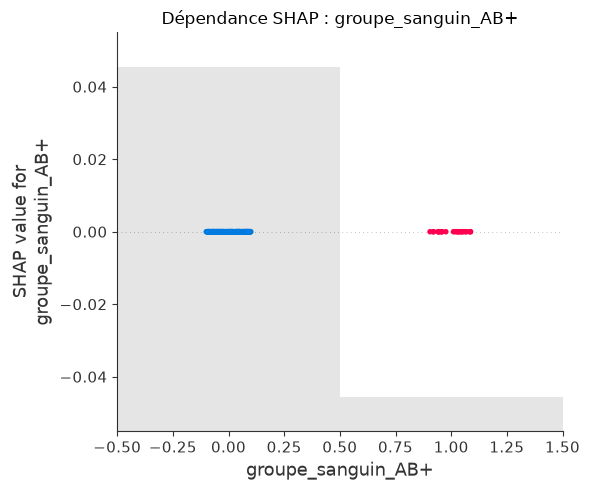

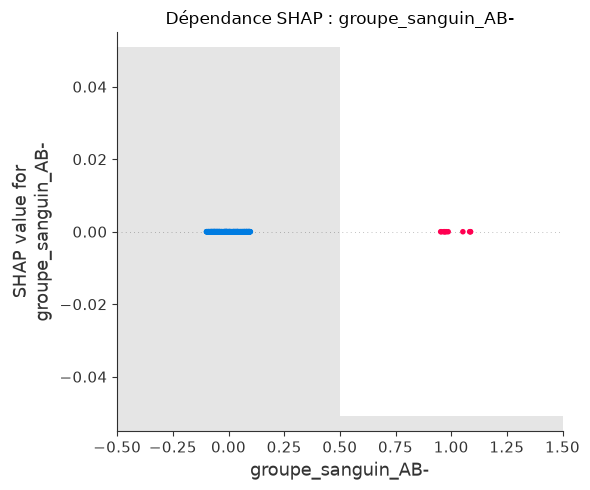

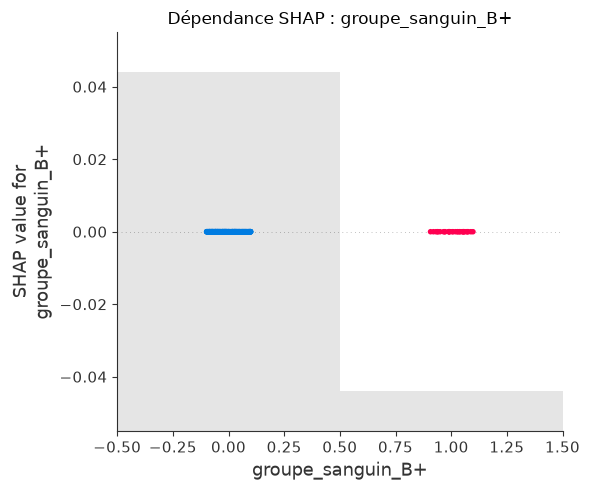

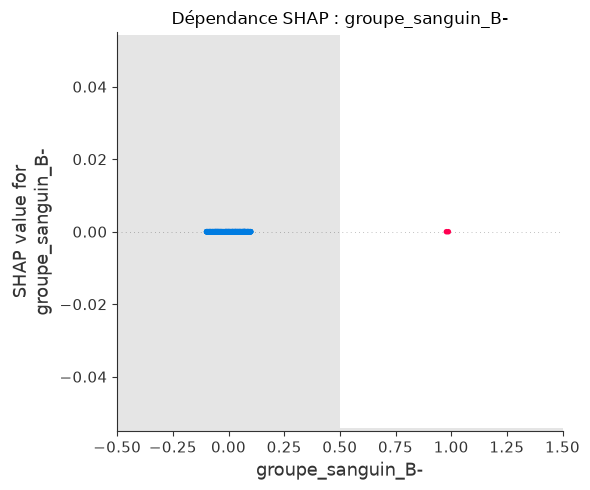

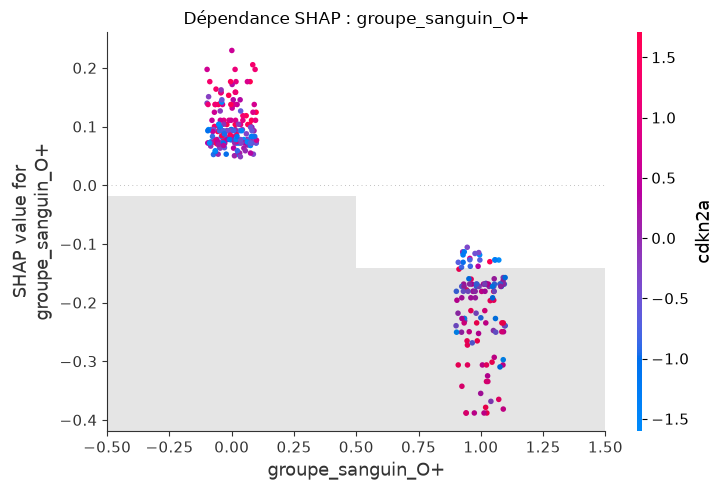

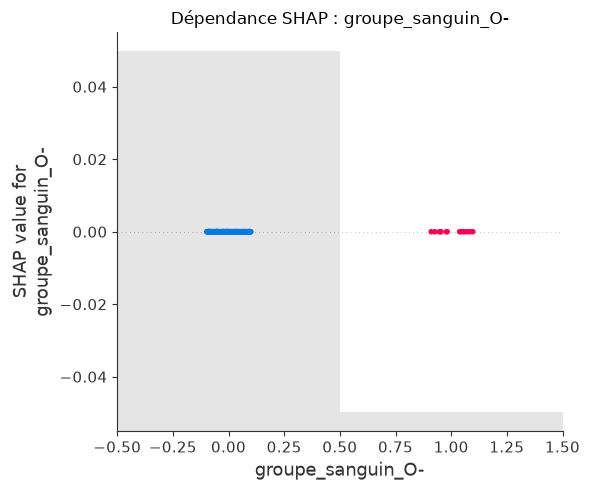

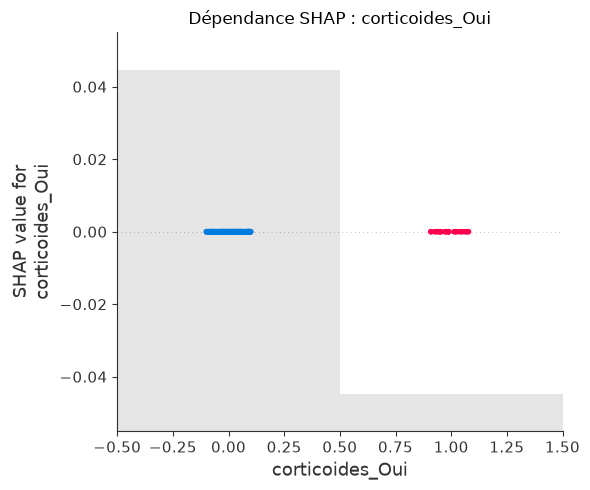

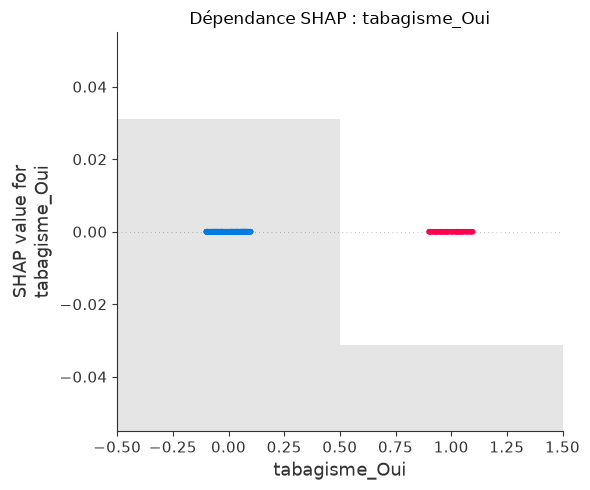

Contributions par groupe : diabete_type_2


,count,mean,median
diabete_type_2,,,
-0.286038,285,0.0,0.0
2.527454,13,0.0,0.0
5.340947,2,0.0,0.0


Contributions par groupe : hypertension


,count,mean,median
hypertension,,,
-0.268765,283,0.0,0.0
3.090800,15,0.0,0.0
6.450366,1,0.0,0.0
9.809932,1,0.0,0.0


Contributions par groupe : maladie_cardiovasculaire


,count,mean,median
maladie_cardiovasculaire,,,
-0.223962,280,0.0,0.0
3.848072,19,0.0,0.0
7.920105,1,0.0,0.0


... (24 outputs left out)

Contributions par groupe : corticoides_Oui


,count,mean,median
corticoides_Oui,,,
0.0,272,0.0,0.0
1.0,28,0.0,0.0


Contributions par groupe : tabagisme_Oui


,count,mean,median
tabagisme_Oui,,,
0.0,235,0.0,0.0
1.0,65,0.0,0.0


In [ ]:
for variable in xgb_X_test_prep.columns:
    shap.plots.scatter(
        xgb_shap_values[:, variable],
        color=xgb_shap_values,
        show=False
    )
    plt.title(f'Dépendance SHAP : {variable}')
    plt.tight_layout()
    plt.show()

for variable in xgb_X_test_prep.columns:
    if xgb_X_test_prep[variable].nunique() <= 10:
        analyse_groupes = pd.DataFrame({
            variable: xgb_X_test_prep[variable],
            'contribution_SHAP': contributions_shap[variable]
        }).groupby(variable)['contribution_SHAP'].agg(
            ['count', 'mean', 'median']
        )

        print(f'Contributions par groupe : {variable}')
        display(analyse_groupes.round(4))

Patient P274 : probabilité 0.998, réalité 1


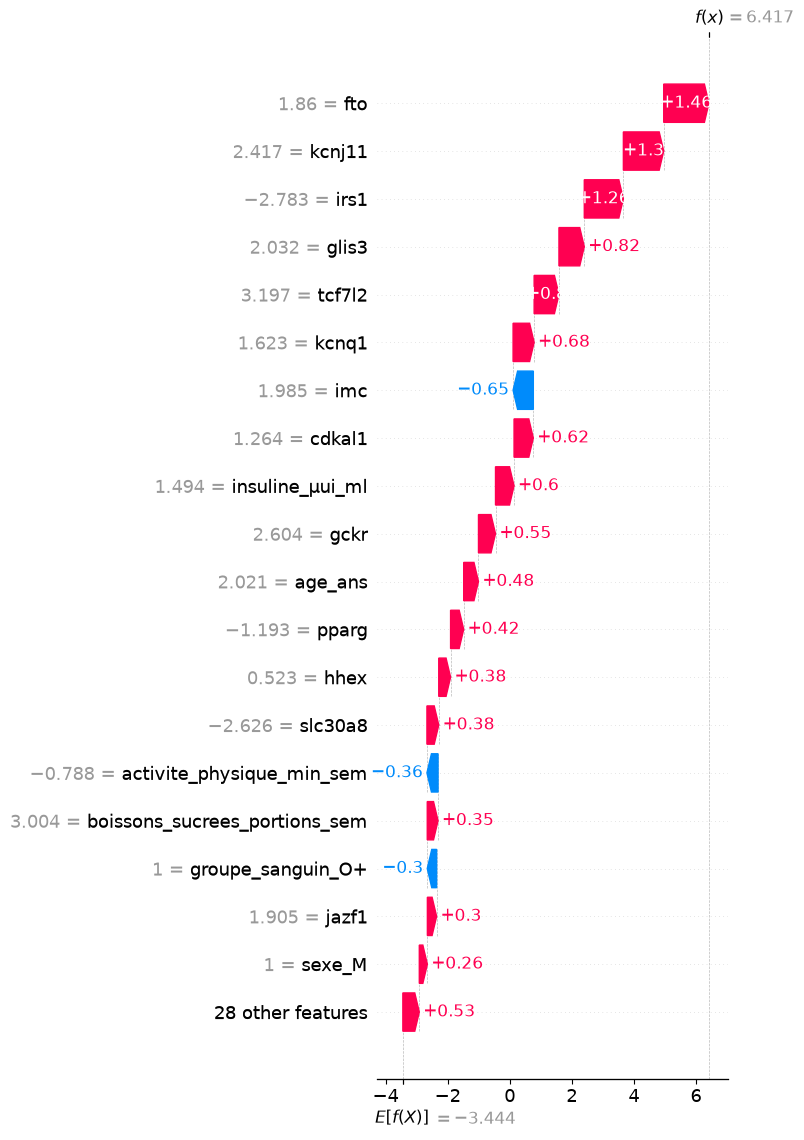

In [117]:
xgb_test_proba = xgb_best.predict_proba(X_test)[:, 1]
i_patient = int(np.argmax(xgb_test_proba))
print(f"Patient {X_test.index[i_patient]} : probabilité {xgb_test_proba[i_patient]:.3f}, réalité {y_test.iloc[i_patient]}")

shap.plots.waterfall(xgb_shap_values[i_patient], max_display=20, show=False)
plt.tight_layout()
plt.show()

In [118]:
from math import exp

passager = xgb_X_test_prep.iloc[[i_patient]]
explication_passager = xgb_shap_values[i_patient]
analyse_passager = pd.DataFrame({
    'valeur_utilisee': passager.iloc[0],
    'contribution_SHAP': explication_passager.values
})
analyse_passager['amplitude'] = analyse_passager['contribution_SHAP'].abs()
analyse_passager['sens'] = analyse_passager['contribution_SHAP'].apply(
    lambda valeur: 'vers glycémie élevée' if valeur > 0 else ('vers glycémie non élevée' if valeur < 0 else 'neutre')
)
analyse_passager = analyse_passager.sort_values('amplitude', ascending=False)
display(analyse_passager.round(4))

for variable, ligne in analyse_passager.head(3).iterrows():
    print(f"{variable} = {ligne['valeur_utilisee']:g} : "
          f"{ligne['contribution_SHAP']:+.3f} log-odds ({ligne['sens']}).")

score_base = float(explication_passager.base_values)
score_reconstruit = score_base + float(explication_passager.values.sum())
probabilite_base = 1 / (1 + exp(-score_base))
probabilite_reconstruite = 1 / (1 + exp(-score_reconstruit))
probabilite_modele = xgb_model.predict_proba(passager)[0, 1]
print(f'Probabilite associee au score de base : {probabilite_base:.1%}')
print(f'Probabilite reconstruite avec SHAP : {probabilite_reconstruite:.1%}')
print(f'Probabilite fournie par XGBoost : {probabilite_modele:.1%}')

,valeur_utilisee,contribution_SHAP,amplitude,sens
fto,1.8599,1.4567,1.4567,vers glycémie élevée
kcnj11,2.4171,1.2999,1.2999,vers glycémie élevée
irs1,-2.7827,1.2591,1.2591,vers glycémie élevée
glis3,2.0321,0.8161,0.8161,vers glycémie élevée
tcf7l2,3.1971,0.7994,0.7994,vers glycémie élevée
kcnq1,1.6227,0.6783,0.6783,vers glycémie élevée
imc,1.9853,-0.6522,0.6522,vers glycémie non élevée
cdkal1,1.2641,0.6209,0.6209,vers glycémie élevée
insuline_µui_ml,1.4945,0.5973,0.5973,vers glycémie élevée
gckr,2.6038,0.5486,0.5486,vers glycémie élevée


fto = 1.85991 : +1.457 log-odds (vers glycémie élevée).
kcnj11 = 2.41714 : +1.300 log-odds (vers glycémie élevée).
irs1 = -2.78275 : +1.259 log-odds (vers glycémie élevée).
Probabilite associee au score de base : 3.1%
Probabilite reconstruite avec SHAP : 99.8%
Probabilite fournie par XGBoost : 99.8%


In [119]:
X_train_fe = feature_engineering(X_train)
display(X_train_fe.groupby(y_train)["imc"].median().rename("imc_median"))
print(f"AUC de l'IMC seul : {roc_auc_score(y_train, X_train_fe['imc']):.3f}")

imc_corr = X_train_fe.select_dtypes("number").corr("spearman")["imc"].drop("imc")
imc_corr.sort_values(key=abs, ascending=False).head(6)

diabete
0    25.403627
1    29.223831
Name: imc_median, dtype: float64

AUC de l'IMC seul : 0.649


insuline_µui_ml    0.551987
tcf7l2             0.279306
pparg             -0.264590
irs1              -0.256585
fto                0.223850
kcnj11             0.197111
Name: imc, dtype: float64